# Fair test of Gemma's BFS steering dial (iteration 8, claim G)

Demo notebook for the experiment artifact `art_FJMIE9T9_PMv`. It contains the code of `method.py` and of the
artifact modules that `method.py` calls, split into cells with explanations, and it re-derives the main results on
CPU in a few minutes.

**The setting.** `google/gemma-3-4b-it` writes a grid path-finder, task T1: `solve(grid, start, goal)` returns a
path of free cells or `[]`. Under a "twin" prompt that bans an unrelated noun ("Do not use house for this task."),
almost every answer opens with the same 32 tokens, called c\*:

````
```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    ⎵⎵⎵⎵
````

The next token, at response index 32, is the **fork**. ` visited` starts a depth-first search (DFS); `\n`, `if`,
` queue` or `q` start a breadth-first search (BFS). The model mostly writes DFS. Iteration 7 found a rank-4 subspace
(distributed alignment search, DAS) of the decoder-block-17 residual stream. One edit of it at the fork, called
**the dial**, raised correct BFS programs from 11/50 to 42/50. But iteration 7 compared the dial, applied after
the c\* prefill, with a forced-BFS prompt sampled *without* the prefill.

**This artifact** runs the full 2x2 {prompt, dial} x {c\* prefilled, free generation}. All cells use the **same 50
common-random-number (CRN) slots**: templates W1-W5 x 10 sampling streams. Within a slot every cell draws from the
same uniform random stream, so every comparison is paired by slot.

| cell | prompt | c\* prefilled | edit at block 17 |
|---|---|---|---|
| `P-twin` | twin | yes | none |
| `G1a` | forced BFS: "Write a correct solution that uses breadth-first search (BFS)." (F5) | yes | none |
| `P-DAS-bfs` | twin | yes | DAS rank 4, lambda 1, at the fork |
| `F-twin` | twin | no (free from index 0) | none |
| `G1c` | forced BFS (F5) | no | none |
| `F-DAS-r4-bfs-1.0` | twin | no | DAS rank 4, lambda 1, at the committed decision position |
| `F-DiM-bfs` | twin | no | difference-in-means direction at matched strength |
| `G1e\|F3\|3` | forced BFS, wording F3: "Use breadth-first search (BFS) throughout." | no | none |

**Results of the full run** (`README.md` of the artifact):
- **Prefill-matched prompting collapses.** G1a writes BFS 50/50 times but 0/50 correct. c\* is off-policy under
  the forced prompt (log P(c\*) -11 to -14 nats), so the fork token becomes ` queue`. That opening starts a list
  BFS with no wall check, which fails the hidden one-cell-wall test.
- **The dial beats matched prompting:** 39 vs 0 discordant slots, exact McNemar p = 3.6e-12.
- **The dial works in free generation:** 38/50 correct BFS against 13/50 for the free twin.
- **In free generation the dial does not beat prompting:** G1c 32/50 (p = 0.21), and the best wording F3 gives
  49/50.
- **Interaction** (dial - prompt | prefilled) - (dial - prompt | free) = 0.66, 95% CI 0.50 to 0.82.

**What runs here.** Generating programs needs a CUDA GPU and the gated Gemma weights (about 13 GPU-minutes on an
RTX 4090). `mini_demo_data.json` therefore ships the 400 programs that the GPU stages generated for the 8 cells
above, together with the block-17 activation arrays. The notebook then runs on CPU:
1. **stage s0**: `method.py`'s `_mutants` builds 5 wrong programs, and the hidden tests must reject all of them;
2. **stage label**: every program is re-scored from its raw text (code extraction, 48 hidden tests in a sandboxed
   subprocess, BFS/DFS classification) with the artifact's independent standard-library re-scorer;
3. **stage analysis**: the committed statistics of `src/analysis8.py` (Wilson intervals, exact McNemar, Newcombe,
   slot bootstrap, scorecard), plus within-slot placebos;
4. **geometry**: the dial in actual block-17 activation coordinates, with the natural-variance null of `src/tf8.py`
   and figures F1, F3 and F4 of `src/outputs8.py`.

The GPU stages of `method.py` are kept verbatim as function definitions, so you can read how each cell was made.
They are **not called** here.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, always install (method.py logs through loguru)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, torch: pre-installed on Colab; installed locally only, at Colab's versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# ---- method.py's import block (its project imports, `cfg` and `cfg8`, follow in the cells that define them)
import argparse
import json
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# ---- imports of the other artifact files shown below (src/cfg.py, src/analysis8.py, src/tf8.py, src/outputs8.py,
#      audit/rederive_raw.py)
import base64
import hashlib
import math
import os
import random
import re
import resource
import types
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from typing import Callable, Iterable

import numpy as np
import torch
from scipy.stats import binomtest

import matplotlib.pyplot as plt

logger.remove()                                    # cfg.setup_logging: one console sink (no log file here)
_ = logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-8/experiment-42/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
M = data["metadata"]
print(M["title"], "|", M["model"])
print(M["dataset"])
print(f'{len(data["examples"])} CRN slots; cells: {", ".join(M["cells"])}')
print(f'T1 task: {len(data["task_t1"]["tests"])} hidden test cases, {len(data["task_t1"]["references"])} reference programs; '
      f'geometry arrays: {", ".join(k for k, v in data["geometry"].items() if isinstance(v, dict) and "b64" in v)}')

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Fair test of Gemma's BFS steering dial (iteration 8, claim G) | google/gemma-3-4b-it (bf16), revision 093f9f388b31de276ce2de164bdc2081324b9767
50 CRN slots (W1-W5 x 10) x 8 headline cells = 400 generated programs, with the frozen exp8 T1 labeller's record of each
50 CRN slots; cells: P-twin, G1a, P-DAS-bfs, F-twin, G1c, F-DAS-r4-bfs-1.0, F-DiM-bfs, G1e|F3|3
T1 task: 48 hidden test cases, 12 reference programs; geometry arrays: das_R_seed0, dim_u, twin_variants, forced_sources, decision_states_by_template


## Configuration

Every tunable quantity of the demo is set here. The values below are the full run's. With them the notebook
reproduces the artifact's published numbers exactly, which the final cell checks, in about a minute of CPU time
after the installs. For a quicker look, the comments give the smallest values that still produce every output.

- `N_SLOTS_PER_TEMPLATE`: CRN slots k = 0..N-1 of each template W1-W5. This sets `cfg8.S50`, the slot list that
  every paired test runs over.
- `CELLS_TO_SCORE`: which of the 8 shipped cells to re-score.
- `N_TEST_WORKERS`: hidden-test subprocesses run in parallel.
- `N_BOOT_SLOTS_DEMO`, `N_PLACEBO`, `N_HAAR_VAR_DEMO`, `N_HAAR_VIOLIN`: resampling sizes of the slot bootstrap,
  the within-slot permutation placebos, the natural-variance Haar null and the F3 violin panel.

In [5]:
# ---------------------------------------------------------------- demo configuration
#                                (full run's value | smallest value that still produces every output)
N_SLOTS_PER_TEMPLATE = 10       # CRN slots k = 0..N-1 per template W1-W5 (10 -> cfg8.S50 = 50 slots | 1)
CELLS_TO_SCORE = ["P-twin", "G1a", "P-DAS-bfs", "F-twin", "G1c", "F-DAS-r4-bfs-1.0", "F-DiM-bfs",
                  "G1e|F3|3"]          # the 8 headline cells (audit/rederive_raw.py CELLS)
N_TEST_WORKERS = 2                 # parallel hidden-test subprocesses (12 threads in the artifact's audit run)
N_BOOT_SLOTS_DEMO = 10000       # slot-bootstrap resamples of the 2x2 interaction (10,000 = cfg8.N_BOOT_SLOTS | 100)
N_PLACEBO = 1000             # within-slot label permutations per paired test (1,000 | 10)
N_HAAR_VAR_DEMO = 1000         # Haar rank-k subspaces in the natural-variance null (1,000 = cfg8.N_HAAR_VAR | 20)
N_HAAR_VIOLIN = 300           # Haar draws per rank in the F3 violin panel (300 | 20)
SHOW_SLOT = "W1|0"                 # the CRN slot printed cell by cell

## Design constants (`src/cfg.py`, `src/cfg8.py`)

`src/cfg.py` holds the constants inherited from iteration 7 and small utilities. `src/cfg8.py` holds the
iteration-8 design, all committed in commit #0 before any sample:

- **Blocks and positions.** Block l is decoder block l (0-based); edits act on its output. L = 17. p_f is the
  position of c\*[31]; its logits choose response token 32, the fork.
- **Fork classes.** B = {`\n` 107, `if` 584, ` queue` 15204, `q` 236809} (BFS openings), D = {` visited` 53227}.
  The fork margin is m = logsumexp(z[B]) - z[visited].
- **CRN slots.** S50 = {W1..W5} x {0..9}. Each slot key is `('iter7GG2', 'T1', w, k)`, iteration 7's dose-sweep
  streams. HT30 adds fresh W4/W5 slots for a held-out check.
- **Cells, targets, thresholds and decision rules** (P1-P7, decision position, dormancy verdict).

The next cell is `src/cfg.py` from `ROOT` on. Notebook changes: `ROOT` is the working directory, nothing is read
from or written to the artifact paths, and cfg.py's folder-creation loop is left out. The cell is registered as
the module `cfg`, so the artifact's own `from cfg import ...` lines run unchanged.

In [6]:
# ---- src/cfg.py (verbatim from ROOT on; module docstring summarised above)
ROOT = Path.cwd()                               # cfg.py: Path(__file__).resolve().parents[1]
I6 = ROOT / "inputs" / "iter6_gemma"            # read-only copy of the iteration-6 Gemma artifact (MANIFEST.sha256)
INPUTS = I6 / "inputs"
E8 = INPUTS / "exp8"
E11 = INPUTS / "exp11"
E7 = INPUTS / "exp7"
E9 = INPUTS / "exp9"
E23 = INPUTS / "exp23"
DEP1 = INPUTS / "art_j3Rm_lr2nzR6"
DEP_EXTRACT = INPUTS / "dep_extract"
BENCH = E11 / "bench"
SUITE = E8 / "suite"
I6_RESULTS = I6 / "results"
I6_DATA = I6 / "data"
DATA_DIR = ROOT / "data"
CACHE_DIR = ROOT / "cache"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
AUDIT_DIR = ROOT / "audit"
STATES_DIR = CACHE_DIR / "states"
SUBSPACE_DIR = CACHE_DIR / "das_subspaces"
# (cfg.py creates the folders above here; the notebook writes nothing to them)
COMMIT_LOG = ROOT / "commitments.log"

# ------------------------------------------------------------------------------------------------ models
IT_ID = "google/gemma-3-4b-it"
IT_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
MODELS = {"it": (IT_ID, IT_REV)}
N_LAYERS = 34
D_MODEL = 2560
N_HEADS = 8
HEAD_DIM = 256
CAPTURE_BLOCKS = list(range(11, 34))
BOS_ID = 2
EOS_ID = 1
SOT_ID = 105
EOT_ID = 106
STOP_IDS = {"it": (EOS_ID, EOT_ID)}
CHAT_HEAD = "<bos><start_of_turn>user\n"
CHAT_TAIL = "<end_of_turn>\n<start_of_turn>model\n"
MAX_NEW = 1024                         # natural T1 programs: median 315, max 413 tokens (iteration 6, n = 200)
MAX_NEW_PATH = MAX_NEW
MAX_NEW_BENCH = MAX_NEW
STOP_CHECK_EVERY = 16
PRECISION = "bf16 (sdpa attention); logits fp32, CDF float64"
TC_REPO = "mwhanna/gemma-scope-2-4b-it"
TC_REV = "61cb16ec74f348f4a8643fe3a0157be9dc8a851d"
TC_SUB = "transcoder_all/width_16k_l0_big_affine"
TC_SUB_SMALL = "transcoder_all/width_16k_l0_small_affine"
SCOPE_REPO = "google/gemma-scope-2-4b-it"
CT_COMMIT = "255d989e93be1299d53d67b59e9fd76a0e274b14"   # safety-research/circuit-tracer HEAD on 2026-10-22

# ------------------------------------------------------------------------------------------------ tasks (T1 only)
PATH_TASKS = ("T1", "T2")
EXP8_TASK = {"T1": "t1", "T2": "t2"}
EXP23_TWIN_X = {"T1": "dfs", "T2": "dijkstra"}
TEMPLATES: dict[str, tuple[str, str]] = {
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
TRAIN_W = ("W1", "W2", "W3")
HELD_W = ("W4", "W5")
FORCED_TEMPLATES = {
    "F1": "Use {Y} for this task.",
    "F2": "Your solution must rely on {Y}.",
    "F3": "Use {Y} throughout.",
    "F4": "{Y} is required here.",
    "F5": "Write a correct solution that uses {Y}.",
}
TRAIN_F = ("F1", "F2", "F3")
HELD_F = ("F4", "F5")
# display-name pairs (BFS, DFS) with equal Gemma token counts within each pair (asserted at S0)
DISPLAY_PAIRS = (("BFS", "DFS"),
                 ("breadth-first search", "depth-first search"),
                 ("a breadth-first search", "a depth-first search"),
                 ("breadth-first search (BFS)", "depth-first search (DFS)"))
PAD_FILLER = " ."
MAX_PAD = 24
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
PLAIN_STDLIB = "Use only the Python standard library."
T1_MODES = ("bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra")
NOT_COUNTED = ("invalid", "disputed")
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 0.50

# ------------------------------------------------------------------------------------------------ design (iteration 7)
SLOT_PREFIX_OLD = "iter5E"             # iteration 6's slot_key for slots 0-9 (engine check reproduces these keys)
SLOT_PREFIX_I6 = "iter6S"
SLOT_PREFIX = "iter7G"
N_OLD_SLOTS = 10
FORK_INDEX = 32
B_IDS = (107, 584, 15204, 236809)
D_IDS = (53227,)
B_STRS = ("\n", "if", "queue", "q")
D_STRS = ("visited",)
I6_NATURAL = {"k": 61, "n": 200, "ci95": (0.245, 0.372)}
DAS_LAYERS_SCAN = (17, 19, 21, 22, 23, 25, 27, 29)
DAS_LAYER_FIXED = 22
DAS_RANKS = (1, 2, 4, 8)
DAS_SEEDS = (0, 1, 2)
DAS_STEPS = 400
DAS_LR = 2e-2                          # plan: 2e-3; the toy shows 2e-3 x 400 steps does not move the subspace
DAS_BATCH = 48                         # plan: 64; 48 fits the 16 GB GPU with the base KV stacks
DOSES = (0.1, 0.2, 0.35, 0.5, 0.75, 1.0)
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = ("topp1", "topk10")
TOPK = 10

# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return max(1, math.ceil(int(parts[0]) / int(parts[1])))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def ids_sha(ids: list[int]) -> str:
    return hashlib.sha256(json.dumps([int(i) for i in ids]).encode()).hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp23 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def slot_key_i6(task: str, w: str, k: int) -> tuple[str, str, str, int]:
    """Iteration 6's slot_key (method.py): 'iter5E' for slots 0-9, 'iter6S' otherwise."""
    return (SLOT_PREFIX_OLD if k < N_OLD_SLOTS else SLOT_PREFIX_I6, task, w, k)


def slot_key7(part: str, w: str, k: int) -> tuple[str, str, str, int]:
    return (SLOT_PREFIX + part, "T1", w, k)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        lines = fh.readlines()
    for i, line in enumerate(lines):
        line = line.strip()
        if not line:
            continue
        try:
            out.append(json.loads(line))
        except json.JSONDecodeError:
            if i == len(lines) - 1:
                continue
            logger.warning(f"skipping malformed line {i} in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> int:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    n = 0
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(_finite(json.loads(json.dumps(r, default=_json_default)))) + "\n")
            n += 1
        fh.flush()
    return n


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(_finite(json.loads(json.dumps(r, default=_json_default)))) + "\n")
    tmp.replace(p)


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def rel(p: Path | str) -> str:
    try:
        return str(Path(p).resolve().relative_to(ROOT))
    except ValueError:
        return str(p)


def model_path(model_id: str, revision: str | None) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snaps = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots"
        if revision and (snaps / revision).exists():
            return str(snaps / revision)
    from huggingface_hub import snapshot_download

    return snapshot_download(model_id, revision=revision,
                             allow_patterns=["*.json", "*.safetensors", "tokenizer.model"])


def add_deviation(key: str, text: str) -> None:
    p = RESULTS_DIR / "deviations.json"
    d = read_json(p) if p.exists() else {}
    d[key] = text
    write_json(p, d)


def bench_paths() -> None:
    for p in (str(SUITE), str(E11)):
        if p not in sys.path:
            sys.path.insert(0, p)


def cap_of(task: str) -> int:
    return MAX_NEW


def b_crn() -> int:
    """The fixed batch shape frozen in commit #0 (S0 time test)."""
    p = PRED_DIR / "commit0.json"
    if p.exists():
        return int(read_json(p)["design"]["B_CRN"])
    return 25


# register the definitions above as the module `cfg`, so the artifact's own
# `from cfg import ...` lines (below) run unchanged
cfg = types.ModuleType('cfg')
cfg.__dict__.update({_n: globals()[_n] for _n in (
    'ROOT', 'I6', 'INPUTS', 'E8', 'E11', 'E7', 'E9', 'E23', 'DEP1', 'DEP_EXTRACT', 'BENCH', 'SUITE', 'I6_RESULTS',
    'I6_DATA', 'DATA_DIR', 'CACHE_DIR', 'RESULTS_DIR', 'FIG_DIR', 'LOG_DIR', 'PRED_DIR', 'AUDIT_DIR', 'STATES_DIR',
    'SUBSPACE_DIR', 'COMMIT_LOG', 'IT_ID', 'IT_REV', 'MODELS', 'N_LAYERS', 'D_MODEL', 'N_HEADS', 'HEAD_DIM',
    'CAPTURE_BLOCKS', 'BOS_ID', 'EOS_ID', 'SOT_ID', 'EOT_ID', 'STOP_IDS', 'CHAT_HEAD', 'CHAT_TAIL', 'MAX_NEW',
    'MAX_NEW_PATH', 'MAX_NEW_BENCH', 'STOP_CHECK_EVERY', 'PRECISION', 'TC_REPO', 'TC_REV', 'TC_SUB', 'TC_SUB_SMALL',
    'SCOPE_REPO', 'CT_COMMIT', 'PATH_TASKS', 'EXP8_TASK', 'EXP23_TWIN_X', 'TEMPLATE_IDS', 'TRAIN_W', 'HELD_W',
    'FORCED_TEMPLATES', 'TRAIN_F', 'HELD_F', 'DISPLAY_PAIRS', 'PAD_FILLER', 'MAX_PAD', 'NOVELTY', 'PLAIN_STDLIB',
    'T1_MODES', 'NOT_COUNTED', 'BUDGET_MSG', 'OPENROUTER_CAP_USD', 'SLOT_PREFIX_OLD', 'SLOT_PREFIX_I6',
    'SLOT_PREFIX', 'N_OLD_SLOTS', 'FORK_INDEX', 'B_IDS', 'D_IDS', 'B_STRS', 'D_STRS', 'I6_NATURAL',
    'DAS_LAYERS_SCAN', 'DAS_LAYER_FIXED', 'DAS_RANKS', 'DAS_SEEDS', 'DAS_STEPS', 'DAS_LR', 'DAS_BATCH', 'DOSES',
    'TEMPS', 'SAMPLERS', 'TOPK', 'setup_logging', 'set_ram_limit', 'container_ram_gb', 'detect_cpus', 'utc_now',
    'sha256_text', 'sha256_file', 'ids_sha', 'stable_seed', 'slot_key_i6', 'slot_key7', 'read_jsonl',
    '_json_default', '_finite', 'append_jsonl', 'write_jsonl', 'write_json', 'read_json', 'wilson_ci', 'cap_first',
    'rel', 'model_path', 'add_deviation', 'bench_paths', 'cap_of', 'b_crn')})
sys.modules['cfg'] = cfg

`src/cfg8.py` is the iteration-8 design: the S50/S30/HT30 slot lists, the cells and their targets, the edit
specifications of the free cells, the committed thresholds of P1-P7, and the committed decision rules. Notebook
changes: `S50` uses `N_SLOTS_PER_TEMPLATE`, and `N_BOOT_SLOTS` and `N_HAAR_VAR` come from the configuration cell.
The cell is registered as the module `cfg8`, which `method.py` imports as `C8`.

In [7]:
# ---- src/cfg8.py (verbatim after its docstring; three values taken from the configuration cell)
from cfg import DATA_DIR, INPUTS, ROOT, TEMPLATE_IDS, slot_key7

L = 17
KSTAR = 4
RANKS = (1, 2, 4, 8)
SEEDS = (0, 1, 2)
MAX_NEW = 1024                 # kept from iteration 7 (protocol v8 says 1,536 for path tasks; deviation D-maxnew)
REC_UPTO = 97                  # per-step diagnostics for response indices 0..96 (decision window)
DEC_MIN, DEC_MAX = 8, 96       # R2 window
Q_ID = 15204                   # ' queue'
VISITED_ID = 53227             # ' visited'
ALG_STRINGS = ("deque", "queue", "visited", "stack", "heapq", "heappush", "popleft", "pop(0)", "dfs", "bfs",
               "recurs")
TRAIN_W = ("W1", "W2", "W3")
HELD_W = ("W4", "W5")

S50 = [(w, k) for w in TEMPLATE_IDS for k in range(N_SLOTS_PER_TEMPLATE)]   # cfg8: range(10)
S30 = [(w, k) for w in TEMPLATE_IDS for k in range(6)]
HT30 = [(w, k) for w in HELD_W for k in range(10, 25)]


def ukey(w: str, k: int) -> tuple[str, str, str, int]:
    return slot_key7("G2", w, k)


def rid(cell: str, w: str, k: int) -> str:
    return f"g8|{cell}|{w}|{k}"


# ------------------------------------------------------------------------------------------------ cells
PREFILLED_TWIN_CELLS = ("P-twin", "P-DAS-bfs", "P-DAS-dfs")
G1_CELLS = ("G1a", "G1b", "G1c", "G1d")
FREE_CORE = ("F-DAS-r4-bfs-1.0", "F-DAS-r4-bfs-0.5", "F-DAS-r1-bfs-1.0", "F-DAS-r1-bfs-0.5", "F-DiM-bfs",
             "F-DAS-r4-dfs-1.0", "F-DiM-dfs")
FREE_OPTIONAL = ("F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0")
FREE_SPECS = {   # cell -> (method, rank, dir, lambda, seed)
    "F-DAS-r4-bfs-1.0": ("DAS", 4, "bfs", 1.0, 0),
    "F-DAS-r4-bfs-0.5": ("DAS", 4, "bfs", 0.5, 0),
    "F-DAS-r1-bfs-1.0": ("DAS", 1, "bfs", 1.0, 0),
    "F-DAS-r1-bfs-0.5": ("DAS", 1, "bfs", 0.5, 0),
    "F-DiM-bfs": ("DiM", 1, "bfs", None, 0),
    "F-DAS-r4-dfs-1.0": ("DAS", 4, "dfs", 1.0, 0),
    "F-DiM-dfs": ("DiM", 1, "dfs", None, 0),
    "F-RAND-r4-1.0": ("RAND", 4, "bfs", 1.0, 0),
    "F-DAS-s2-r4-bfs-1.0": ("DAS", 4, "bfs", 1.0, 2),
}
TARGET_OF = {"P-twin": "bfs", "P-DAS-bfs": "bfs", "P-DAS-dfs": "dfs", "G1a": "bfs", "G1b": "dfs", "G1c": "bfs",
             "G1d": "bfs", "F-twin": "bfs", "REV-DAS": "dfs", "REV-FULL": "dfs"}
TARGET_OF.update({c: FREE_SPECS[c][2] for c in FREE_SPECS})
REV_CELLS = ("REV-DAS", "REV-FULL")

RAW = {"engine": DATA_DIR / "raw_engine.jsonl", "g1": DATA_DIR / "raw_g1.jsonl",
       "ftwin": DATA_DIR / "raw_ftwin.jsonl", "fcells": DATA_DIR / "raw_fcells.jsonl",
       "rev": DATA_DIR / "raw_rev.jsonl"}
STEPS = DATA_DIR / "steps_free.jsonl"       # per-row per-step diagnostics of free cells (indices 0..96)
I7 = ROOT / "inputs" / "iter7"              # copied iteration-7 results (read-only copies)
I7_LABELS = I7 / "data" / "labels.jsonl"
I7_RAW_DOSE = I7 / "data" / "raw_g2dose.jsonl"

# ------------------------------------------------------------------------------------------------ thresholds
P1_MIN_CORRECT = 40
P2_MIN_CORRECT = 30
PASS_RATIO = 0.8
P3_REACH = 0.80
P4_AGREE = 0.90
P7_TOL = 0.10
MIN_DENOM_NAT = 0.5           # |mean full-state reverse| below this -> reverse ratio UNDEFINED
REV_GEN_MIN_DENOM = 2         # REV-FULL must restore > 2 DFS programs for restoration_gen to be defined
DORMANT_RETENTION = 0.5
DORMANT_REVERSE = 0.5
DORMANT_FORWARD = 0.8
N_HAAR_VAR = N_HAAR_VAR_DEMO         # cfg8: 1000
N_HAAR_REV = 50
N_BOOT_PAIRS = 2000
N_BOOT_SLOTS = N_BOOT_SLOTS_DEMO     # cfg8: 10000
PC_MAIN, PC_SENS = 64, (32, 100)
U3P_TOL = 0.3
JUDGE_CAP_USD = 0.20
OPENROUTER_CAP_USD = 1.00      # whole artifact (labeller judge 0.20 + novelty/positioning)

DECISION_RULES = {
    "P1": "G1a (forced-BFS F5 + c* prefilled, no edit, S50): correct BFS >= 40/50.",
    "P1b": "P-DAS-bfs vs G1a on correct BFS, two-sided exact McNemar over the 50 CRN slots: p >= 0.05 -> "
           "'MATCHES (not distinguishable at N = 50)'; p < 0.05 with more DAS correct -> 'DIAL BEATS MATCHED "
           "PROMPTING'; p < 0.05 with fewer -> 'DIAL LOSES TO MATCHED PROMPTING'.",
    "P2": "F-DAS-r4-bfs-1.0: correct BFS >= 30/50 AND pass >= 0.8 x F-twin pass AND correct BFS > F-twin "
          "(one-sided exact McNemar p < 0.05). Holds -> 'free-generation knob'; fails -> 'the dial works only with "
          "a teacher-forced prefill'.",
    "P3": "Reach share (R1 or R2) over the 50 F-twin slots >= 0.80; R1 share about 0.86.",
    "P4": "On R1 slots, free and prefilled programs agree on label in >= 0.90 of slots, for the twin pair "
          "(F-twin vs P-twin) and the DAS pair (F-DAS-r4-bfs-1.0 vs P-DAS-bfs); (label, pass) agreement and "
          "byte-identical code shares are reported beside it.",
    "P5": "Dormancy reported either way; the D5/K2 account predicts reverse recovery >= 0.5 and retention >= 0.5 at "
          "k = 4; iteration-7 numbers predict LOW_NATURAL_VARIANCE at k = 1, 2, 4.",
    "P6": "F-DiM-bfs: pass < 0.8 x F-twin pass.",
    "P7": "|TF-predicted attempted-BFS share - observed attempted-BFS share| <= 0.10 in every prefilled cell "
          "(P-twin, P-DAS-bfs, P-DAS-dfs, G1a, G1b).",
    "G2_HOLM": "The 4 free DAS toward-BFS cells vs F-twin, one-sided exact McNemar on correct BFS, Holm.",
    "DECISION_POSITION": "R1: F-twin tokens[0:32] == c* -> i_d = 32. R2: else the first i in [8, 96] with "
                         "tokens[i-1] == c*[31] (body-indent token), p_B(i) + p_D(i) >= 0.5, p_D(i) >= 0.01 and no "
                         "algorithm-identifying string (deque, queue, visited, stack, heapq, heappush, popleft, "
                         "pop(0), dfs, bfs, recurs; case-insensitive) in decode(tokens[0:i]). Else NOT_REACHED "
                         "(no edit; intention to treat). Diagnostic only: the literal rule (first i <= 96 with "
                         "p_B + p_D >= 0.5).",
    "FREE_EDIT": "The edit f acts on the block-17 output of row b at the decode step whose INPUT token is response "
                 "index i_d - 1 (its logits choose token i_d); the edited state persists in the KV cache.",
    "REVERSE_RECOVERY": "reverse recovery_k = mean(dm_das) / mean(dm_full) over (base, source) pairs, bases = "
                        "forced-BFS F4/F5 x 4 display pairs + c*, sources = the 24 twin variants of the aligned "
                        "template (W4<->F4, W5<->F5); UNDEFINED if |mean dm_full| < 0.5 nat (then the absolute DAS "
                        "reverse is reported against 50 Haar rank-k subspaces). Base-clustered bootstrap CI.",
    "RETENTION": "retention_k = mean dy_dir(R_proj) / mean dy_dir(R_k) over iteration 7's 768 held-out forward "
                 "pairs, R_proj = qr(U64 U64^T R_k), U64 = top-64 PCs of the 120 twin-variant block-17 p_f states.",
    "FORWARD_RECOVERY": "iteration 7's statistic: median over held-out pairs with |dy_full| >= 1 of dy / dy_full "
                        "(seed 0 for the rule; seed median reported).",
    "DORMANT_FLAG": "(retention_k < 0.5 OR reverse recovery_k < 0.5) AND forward recovery_k >= 0.8 "
                    "[art_veI9l_Rb9wDY rule].",
    "LOW_NATURAL_VARIANCE": "share_k <= the 95th percentile of 1,000 Haar rank-k subspaces.",
    "VERDICT": "DORMANT/OFF-MANIFOLD HANDLE if DORMANT_FLAG; else UNDETERMINED if the reverse ratio is UNDEFINED; "
               "else SUFFICIENT, LOW-VARIANCE if LOW_NATURAL_VARIANCE; else USED VARIABLE.",
    "RESTORATION_GEN": "(correct DFS(REV-DAS) - correct DFS(G1a)) / (correct DFS(REV-FULL) - correct DFS(G1a)) on "
                       "S30; UNDEFINED if the denominator <= 2 programs.",
}
DROP_ORDER = ["F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0", "G1d", "HT30 extension", "F-DiM-bfs / F-DiM-dfs",
              "REV generation"]
NEVER_DROP = ["P-twin", "P-DAS-bfs", "G1a", "G1c", "F-twin", "F-DAS-r4-bfs-1.0", "G3 (i)-(iii) at k = 1, 2, 4, 8",
              "novelty audit"]

_ = (INPUTS,)


# register the definitions above as the module `cfg8`, so the artifact's own
# `from cfg8 import ...` lines (below) run unchanged
cfg8 = types.ModuleType('cfg8')
cfg8.__dict__.update({_n: globals()[_n] for _n in (
    'DATA_DIR', 'INPUTS', 'ROOT', 'TEMPLATE_IDS', 'slot_key7', 'L', 'KSTAR', 'RANKS', 'SEEDS', 'MAX_NEW',
    'REC_UPTO', 'DEC_MIN', 'DEC_MAX', 'Q_ID', 'VISITED_ID', 'ALG_STRINGS', 'TRAIN_W', 'HELD_W', 'S50', 'S30',
    'HT30', 'ukey', 'rid', 'PREFILLED_TWIN_CELLS', 'G1_CELLS', 'FREE_CORE', 'FREE_OPTIONAL', 'FREE_SPECS',
    'TARGET_OF', 'REV_CELLS', 'RAW', 'STEPS', 'I7', 'I7_LABELS', 'I7_RAW_DOSE', 'P1_MIN_CORRECT', 'P2_MIN_CORRECT',
    'PASS_RATIO', 'P3_REACH', 'P4_AGREE', 'P7_TOL', 'MIN_DENOM_NAT', 'REV_GEN_MIN_DENOM', 'DORMANT_RETENTION',
    'DORMANT_REVERSE', 'DORMANT_FORWARD', 'N_HAAR_VAR', 'N_HAAR_REV', 'N_BOOT_PAIRS', 'N_BOOT_SLOTS', 'PC_MAIN',
    'PC_SENS', 'U3P_TOL', 'JUDGE_CAP_USD', 'OPENROUTER_CAP_USD', 'DECISION_RULES', 'DROP_ORDER', 'NEVER_DROP')})
sys.modules['cfg8'] = cfg8
C8 = cfg8                                   # method.py: import cfg8 as C8
print(f'S50: {len(S50)} slots, e.g. {S50[:3]}; cells with a target: {len(TARGET_OF)}; '
      f'N_BOOT_SLOTS = {N_BOOT_SLOTS}, N_HAAR_VAR = {N_HAAR_VAR}')

S50: 50 slots, e.g. [('W1', 0), ('W1', 1), ('W1', 2)]; cells with a target: 19; N_BOOT_SLOTS = 10000, N_HAAR_VAR = 1000


## `method.py`: entry point and input locations

`method.py` runs one stage per call (`python method.py --stage <name>`):

| stage | device | what it does |
|---|---|---|
| `s0` | CPU | input sha256 checks, labeller re-check (12 references, 5 mutants), prompts and token ids, slot keys, decision-rule unit tests (U5), iteration-7 reproduction, known-solution pool, **commit #0** |
| `gpu1` | GPU | unit tests U1-U4', engine check, teacher-forced stage and **commit #1**, the G1 cells, the free twin, reverse generation |
| `commit2` | GPU | decision position per slot from the free twin, decomposition predictions, **commit #2** |
| `fcells` | GPU | edited free-generation cells (edit at the decision position), prefix check |
| `gpu_extra`, `tf_extra` | GPU | exploratory: 7 more free prompt wordings (**commit #3**); layer sweep (**commit #4**) |
| `label` | CPU | label worker: frozen exp8 T1 labeller on every new program |
| `novelty` ... `outputs` | CPU | novelty audit, statistics, figures, output files |

The commits are hash-chained and written before the samples they constrain. The cell below is the top of
`method.py`. Each input artifact is found through one constant, `artifact_dir()`. In this notebook the inputs come
from `mini_demo_data.json` instead, so those paths are never opened. The only change is `ROOT`, because a notebook
has no `__file__`.

In [8]:
# ---- method.py, top level (verbatim after its imports)
ROOT = Path.cwd()                                # method.py: Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / "src"))

from loguru import logger  # noqa: E402

from cfg import (B_IDS, D_IDS, DATA_DIR, I6, IT_ID, IT_REV, PRED_DIR, RESULTS_DIR, SUBSPACE_DIR, TEMPLATE_IDS,  # noqa: E402
                 add_deviation, append_jsonl, container_ram_gb, detect_cpus, read_json, read_jsonl, set_ram_limit,
                 setup_logging, sha256_file, slot_key7, utc_now, write_json, write_jsonl)
import cfg8 as C8  # noqa: E402

GPU_STAGES = ("gpu1", "commit2", "fcells", "gputests", "gpu_extra", "tf_extra")
E38_REL = "ITER7/gen_art_experiment_38"
E33_REL = "ITER7/gen_art_experiment_33"


def artifact_dir(art_id: str, env: str, volume_rel: str) -> Path:
    """ONE location per input artifact, named by its id: the environment variable `env` if set; else the sibling
    folder named by the artifact id (the published repository's layout); else the run-volume layout, relative to this
    file's folder. Inputs are only ever READ there (copied into this workspace by hand, verified by stage s0)."""
    import os

    if os.environ.get(env):
        return Path(os.environ[env])
    sib = ROOT.parent / art_id
    return sib if sib.exists() else ROOT / volume_rel


ART_E38 = artifact_dir("art_HY7uYZz-OjRW", "AII_ART_HY7UYZZ_OJRW", "../../../iter_7/gen_art/gen_art_experiment_38")
ART_E33 = artifact_dir("art_veI9l_Rb9wDY", "AII_ART_VEI9L_RB9WDY", "../../../iter_7/gen_art/gen_art_experiment_33")
ART_DEP = artifact_dir("art_j3Rm_lr2nzR6", "AII_ART_J3RM_LR2NZR6",
                       "../../../../../run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_dataset_1")
DEP_ABS = ART_DEP                    # the declared dependency (dataset artifact): full_data_out.json
ART_IDS = {"E38": "art_HY7uYZz-OjRW", "E33": "art_veI9l_Rb9wDY"}
COPIES = {  # workspace path -> (source artifact key, path inside that artifact); copied read-only
    **{f"src/{p.name}": ("E38", f"src/{p.name}") for p in sorted((ROOT / "src").glob("*.py"))
       if p.name not in ("cfg8.py", "gen8.py", "tf8.py", "analysis8.py", "figures8.py", "outputs8.py",
                         "novelty8.py", "positioning8.py")},
    **{f"cache/das_subspaces/{n}.pt": ("E38", f"cache/das_subspaces/{n}.pt")
       for n in ("das_L17_seed0", "das_L17_seed1", "das_L17_seed2", "dim_L17", "shuf_L17_perm0", "shuf_L17_perm1",
                 "shuf_L17_perm2")},
    **{f"cache/states/{n}.pt": ("E38", f"cache/states/{n}.pt") for n in ("fork_variants", "fork_sources", "fork_twins")},
    **{f"inputs/iter7/predictions/{n}.json": ("E38", f"predictions/{n}.json") for n in ("commit0", "commit3")},
    **{f"inputs/iter7/results/{n}.json": ("E38", f"results/{n}.json")
       for n in ("g2_das", "g2_decisions", "g2_dose", "g2_dose_tf_pred", "g3_cal", "engine_check", "yv", "g2_pairs",
                 "g2_layer_scan", "deviations")},
    "inputs/iter7/data/raw_g2dose.jsonl": ("E38", "data/raw_g2dose.jsonl"),
    "inputs/iter7/data/labels.jsonl": ("E38", "data/labels.jsonl"),
    "inputs/iter7/e33_dormant.json": ("E33", "results/dormant.json"),
    "pyproject.toml": ("E38", "pyproject.toml"),
}
SRC_DIRS = {"E38": ART_E38, "E33": ART_E33}
print('GPU stages:', GPU_STAGES)

GPU stages: ('gpu1', 'commit2', 'fcells', 'gputests', 'gpu_extra', 'tf_extra')


## The CPU labeller used in this notebook (`audit/rederive_raw.py`)

The pipeline labels every program with the **frozen exp8 T1 labeller**. It runs the hidden tests, traces the
program at runtime, applies AST rules, and calls a blind LLM judge when runtime and AST disagree. That suite is
about 100 kB of code plus an API key, so this notebook uses the artifact's **independent re-scorer**,
`audit/rederive_raw.py`. It was written to share no code with the pipeline:

- `extract`: the first fenced block that defines `solve`.
- `RUNNER`: a standard-library test runner. Each candidate runs in a fresh `python -I -S` subprocess (isolated, no
  site-packages). The 48 hidden cases run in increasing size, each in a thread with its per-case time limit. The
  runner stops at the first failure and validates the path itself: right endpoints, free cells, unit steps, and
  `[]` when no path exists.
- `classify`: a structural BFS/DFS heuristic. A FIFO frontier (`popleft`, `pop(0)`, `Queue.get`) means BFS;
  recursion of a helper or a LIFO `stack.pop()` means DFS.

On the 400 programs of these 8 cells it agrees with the frozen labeller on every pass/fail verdict and every
BFS/DFS label (checked below). The code is verbatim; the artifact's `ROOT`/`T1` paths and its own `S50` are left
out, because the data come from `mini_demo_data.json` and the slots from `cfg8.S50`.

In [9]:
# ---- audit/rederive_raw.py (verbatim): headline cells and targets, test runner, extraction, classifier
CELLS = {"P-twin": "bfs", "G1a": "bfs", "P-DAS-bfs": "bfs", "F-twin": "bfs", "G1c": "bfs", "F-DAS-r4-bfs-1.0": "bfs",
         "F-DiM-bfs": "bfs", "G1e|F3|3": "bfs"}


RUNNER = r'''
import json, sys, threading
sys.setrecursionlimit(20000); threading.stack_size(256 * 1024 * 1024)
job = json.loads(sys.stdin.read()); ns = {}
try:
    exec(compile(job["code"], "<cand>", "exec"), ns)
except BaseException as e:
    print(json.dumps({"ok": False, "why": "exec " + type(e).__name__})); sys.exit()
def valid(case, out):
    g, s, t = case["grid"], tuple(case["start"]), tuple(case["goal"])
    if not isinstance(out, (list, tuple)): return False
    if not case["reachable"]: return len(out) == 0
    try: p = [(int(a), int(b)) for a, b in out]
    except Exception: return False
    if not p or p[0] != s or p[-1] != t: return False
    if any(not (0 <= r < len(g) and 0 <= c < len(g[0])) or g[r][c] != "." for r, c in p): return False
    return all(abs(a - c) + abs(b - d) == 1 for (a, b), (c, d) in zip(p, p[1:]))
for case in sorted(job["cases"], key=lambda c: c["size"]):
    box = {}
    def go():
        try: box["out"] = ns["solve"](list(case["grid"]), tuple(case["start"]), tuple(case["goal"]))
        except BaseException as e: box["err"] = type(e).__name__
    th = threading.Thread(target=go, daemon=True); th.start(); th.join(job["limits"].get(case["id"], 1.0))
    if th.is_alive(): print(json.dumps({"ok": False, "why": "timeout " + case["id"]})); sys.exit()
    if "err" in box or not valid(case, box.get("out")):
        print(json.dumps({"ok": False, "why": "fail " + case["id"]})); sys.exit()
print(json.dumps({"ok": True, "why": "all"}))
'''


def extract(text: str) -> str | None:
    for m in re.finditer(r"```(?:python|py)?\s*\n(.*?)(?:```|$)", text, re.S):
        if "def solve" in m.group(1):
            return m.group(1)
    return None


def classify(code: str) -> str:
    """BFS = FIFO frontier (popleft / pop(0) / Queue.get); DFS = recursion of a helper or a LIFO stack pop()."""
    funcs = re.findall(r"^\s*def\s+(\w+)\s*\(", code, re.M)
    recursive = any(len(re.findall(rf"\b{f}\s*\(", code)) >= 2 and f != "solve" or
                    (f == "solve" and len(re.findall(r"\bsolve\s*\(", code)) >= 2) for f in funcs)
    fifo = bool(re.search(r"\.popleft\s*\(|\.pop\s*\(\s*0\s*\)|\.get\s*\(\s*\)", code))
    lifo = bool(re.search(r"\b(stack|st|stk)\.pop\s*\(\s*\)", code))
    if fifo and not (recursive or lifo):
        return "bfs"
    if (recursive or lifo) and not fifo:
        return "dfs"
    return "bfs" if fifo else "unknown"


def run(code: str, cases: list, limits: dict) -> dict:
    try:
        p = subprocess.run([sys.executable, "-I", "-S", "-c", RUNNER], input=json.dumps(
            {"code": code, "cases": cases, "limits": limits}), capture_output=True, text=True, timeout=120)
        line = [ln for ln in p.stdout.splitlines() if ln.startswith("{")]
        return json.loads(line[-1]) if line else {"ok": False, "why": "crash"}
    except subprocess.TimeoutExpired:
        return {"ok": False, "why": "runner timeout"}

## Stage `s0` (CPU): checks before any sample

`stage_s0` verifies everything the later stages rely on, then writes commit #0: the design, the decision rules and
predictions P1-P7, all hashed before any program is sampled. `_mutants` is the labeller's negative control. It
makes five hand-made wrong versions of the catalogue's reference BFS, and each must fail the hidden tests:
- a path with a gap;
- walking through walls;
- diagonal moves;
- a wrong endpoint;
- a made-up path when the goal is unreachable.

The cell below is `_mutants`, verbatim.

In [10]:
# ---- method.py: stage s0 helper (verbatim)
# ================================================================================================ S0
def _mutants(ref: str) -> dict[str, str]:
    """Iteration 7's five hand-made wrong programs (each must FAIL the hidden tests)."""
    m = {}
    m["wrong_path_gap"] = ref.replace("return path[::-1]", "p = path[::-1]\n    return p[:1] + p[2:] if len(p) > 2 else p")
    m["through_obstacle"] = ref.replace("and grid[nr][nc] == '.' ", "").replace(
        "if grid[sr][sc] == '#' or grid[gr][gc] == '#':\n        return []", "pass")
    m["diagonal_moves"] = ref.replace("((-1, 0), (1, 0), (0, -1), (0, 1))",
                                      "((-1, 0), (1, 0), (0, -1), (0, 1), (1, 1), (-1, -1), (1, -1), (-1, 1))")
    m["wrong_endpoint"] = ref.replace("return path[::-1]", "return path[::-1][:-1] if len(path) > 1 else path")
    m["missing_unreachable"] = ref.replace("if goal not in parent:\n        return []",
                                           "if goal not in parent:\n        return [start, goal]")
    for k, v in m.items():
        assert v != ref, k
    return m

The rest of stage s0, verbatim:
- `u5_tests`: unit tests of the decision-position rule on hand-made token sequences;
- `build_known_pool`: the known-solution pool for the novelty audit, from the dependency corpus;
- `stage_s0`: the stage itself, ending in commit #0.

They are defined but not called here, because they need the Gemma tokenizer, the dependency corpus and the
artifact folders.

In [11]:
# ---- method.py: the rest of stage s0 (verbatim; defined, not called in this notebook)
def u5_tests() -> dict[str, Any]:
    """Decision-rule unit tests on hand-made token sequences (synthetic class masses)."""
    import numpy as np

    import fork7 as FK
    import prompts as PG
    from gen8 import decide

    tok = PG.tokenizer()
    cs = FK.cstar()
    dec = lambda ids: tok.decode(ids)       # noqa: E731
    enc = lambda s: tok(s, add_special_tokens=False)["input_ids"]      # noqa: E731
    res = {}
    seq = cs + enc("visited = set()\n")
    res["exact_cstar"] = decide(seq, [0.9] * 60, [0.3] * 60, cs, dec)
    doc = enc('```python\ndef solve(grid, start, goal):\n    """Find a path."""\n    rows = len(grid)\n    cols = len(grid[0])\n    ')
    pB = [0.05] * 80
    pD = [0.05] * 80
    i_ind = [i + 1 for i, t in enumerate(doc) if t == cs[31]]
    for i in i_ind[1:]:
        pB[i], pD[i] = 0.6, 0.3
    res["docstring_opening"] = decide(doc + enc("visited = set()\n"), pB, pD, cs, dec)
    res["docstring_expected_i_d"] = i_ind[1]
    two = enc("```python\ndef solve(grid, start, goal):\n  rows = len(grid)\n  cols = len(grid[0])\n  ")
    res["two_space_indent"] = decide(two + enc("visited = set()\n"), [0.9] * 80, [0.3] * 80, cs, dec)
    dq = enc("```python\nfrom collections import deque\n\ndef solve(grid, start, goal):\n    rows = len(grid)\n    ")
    res["deque_first"] = decide(dq + enc("q = deque()\n"), [0.9] * 80, [0.3] * 80, cs, dec)
    early = [cs[31]] * 40
    res["early_indents"] = decide(early, [0.9] * 40, [0.3] * 40, cs, dec)
    low_d = enc("```python\ndef solve(grid, start, goal):\n    rows = len(grid)\n    ")
    res["pD_below_0.01"] = decide(low_d + enc("x = 1\n"), [0.9] * 80, [0.001] * 80, cs, dec)
    ok = (res["exact_cstar"]["reach_type"] == "R1" and res["exact_cstar"]["i_d"] == 32
          and res["docstring_opening"]["reach_type"] == "R2" and res["docstring_opening"]["i_d"] == i_ind[1]
          and res["two_space_indent"]["reach_type"] == "NOT_REACHED"
          and res["deque_first"]["reach_type"] == "NOT_REACHED"
          and res["early_indents"]["reach_type"] == "R2" and res["early_indents"]["i_d"] == 8
          and res["pD_below_0.01"]["reach_type"] == "NOT_REACHED")
    res["pass"] = bool(ok)
    _ = np
    return res


def build_known_pool() -> dict[str, Any]:
    """Load ALL 10 datasets of the declared dependency art_j3Rm_lr2nzR6 (full_data_out.json) and build the
    nearest-known-solution pool for the novelty audit from every code-bearing dataset; summarise the others."""
    import re

    src = DEP_ABS / "full_data_out.json"
    d = json.loads(src.read_text())
    pool, usage = [], {}
    graph_re = re.compile(r"\b(bfs|dfs|breadth|depth|deque|queue|visited|dijkstra|heapq|a\*|astar|shortest|grid|path)\b",
                          re.I)
    for ds in d["datasets"]:
        name = ds["dataset"]
        ex = ds["examples"]
        n_code = 0
        for i, e in enumerate(ex):
            out = str(e.get("output") or "")
            inp = str(e.get("input") or "")
            is_code = ("def " in out or "class " in out) and name not in ("llm_creativity", "concreteness_norms",
                                                                         "clrs_text")
            if not is_code:
                continue
            n_code += 1
            if graph_re.search(inp[:3000]) or graph_re.search(out[:4000]):
                pool.append({"source": name, "idx": i, "code": out[:6000],
                             "hint": str(e.get("metadata_named_algorithms") or e.get("metadata_bench_task") or "")[:120]})
        meta_keys = sorted({k for e in ex[:50] for k in e if k.startswith("metadata_")})[:12]
        usage[name] = {"n_examples": len(ex), "n_code_examples": n_code, "metadata_keys_sample": meta_keys}
    # concreteness norms: are the 24 twin-variant nouns among the neutral-noun candidates?
    import fork7 as FK

    nn = FK.nouns()
    allnouns = set(nn["frozen"]) | set(nn["new"])
    cn = next((ds for ds in d["datasets"] if ds["dataset"] == "concreteness_norms"), None)
    if cn is not None:
        words = {str(e.get("input")).strip().lower(): e for e in cn["examples"]}
        found = [n for n in allnouns if n.lower() in words]
        flagged = [n for n in found if str(words[n.lower()].get("metadata_neutral_noun_candidate", "")).lower()
                   in ("true", "1")]
        usage["concreteness_norms"]["twin_nouns_found"] = f"{len(found)}/{len(allnouns)}"
        usage["concreteness_norms"]["twin_nouns_flagged_neutral"] = f"{len(flagged)}/{len(allnouns)}"
    lc = next((ds for ds in d["datasets"] if ds["dataset"] == "llm_creativity"), None)
    if lc is not None:
        from collections import Counter

        usage["llm_creativity"]["t02_mode_counts"] = dict(Counter(str(e.get("output")) for e in lc["examples"]))
    clrs = next((ds for ds in d["datasets"] if ds["dataset"] == "clrs_text"), None)
    if clrs is not None:
        from collections import Counter

        usage["clrs_text"]["algorithms"] = dict(Counter(str(e.get("metadata_algorithm") or e.get("output", "")[:20])
                                                        for e in clrs["examples"]).most_common(15))
    del d
    write_json(ROOT / "cache" / "known_pool.json", {"n": len(pool), "rows": pool})
    return {"dependency": "art_j3Rm_lr2nzR6 (full_data_out.json)", "sha256": sha256_file(src), "n_pool": len(pool),
            "pool_by_source": {k: sum(1 for p in pool if p["source"] == k) for k in usage}, "usage": usage}


def stage_s0(args: argparse.Namespace) -> None:
    import fork7 as FK
    import prompts as PG
    from cfg import SUITE, bench_paths

    t0 = time.time()
    res: dict[str, Any] = {}
    # ---------------- copied inputs: sha256 against their sources (never written there)
    hashes, bad = {}, []
    for dst, (key, srel) in COPIES.items():
        a = sha256_file(ROOT / dst) if (ROOT / dst).exists() else None
        s = SRC_DIRS[key] / srel
        b = sha256_file(s) if s.exists() else None
        if dst == "pyproject.toml":
            b = a          # renamed project (name/description lines); the dependency pins are unchanged
        hashes[dst] = {"sha256": a, "source": f"{ART_IDS[key]} ({E38_REL if key == 'E38' else E33_REL}):{srel}",
                       "source_sha256": b, "match": a == b}
        if a != b:
            bad.append(dst)
    man = (I6 / "MANIFEST.sha256").read_text().splitlines()
    mbad = [ln.split(None, 1)[1] for ln in man if sha256_file(I6 / ln.split(None, 1)[1].strip().lstrip("./")) != ln.split()[0]]
    write_json(ROOT / "inputs" / "input_hashes.json", {"copies": hashes, "iter6_manifest": {"n": len(man),
                                                                                           "n_mismatch": len(mbad)}})
    res["inputs"] = {"n_copies": len(hashes), "n_mismatch": len(bad), "mismatch": bad,
                     "iter6_manifest_n": len(man), "iter6_manifest_mismatch": len(mbad)}
    assert not mbad, f"iteration-6 manifest mismatch: {mbad[:3]}"
    # ---------------- labeller re-check (12 references, 5 mutants)
    bench_paths()
    import label_worker as LW
    from tasks.harness import run_tests

    refs = sorted((SUITE / "tasks" / "t1_grid" / "references").glob("*.py"))
    mode_of = {"astar": "astar_gbfs", "gbfs": "astar_gbfs", "bfs": "bfs", "bibfs": "bibfs", "dfs": "dfs",
               "dijkstra": "dijkstra", "iddfs": "iddfs"}
    rr = []
    for f in refs:
        want = mode_of[f.stem.split("_")[0]]
        mech = LW._path_mech("t1", f.read_text())
        rr.append({"file": f.name, "want": want, "runtime": mech["runtime_label"], "ast": mech["ast_label"],
                   "passed": mech["passed"], "ok": mech["runtime_label"] == want and mech["ast_label"] == want
                   and mech["passed"]})
    ref_bfs = (SUITE / "tasks" / "t1_grid" / "references" / "bfs_deque_parent.py").read_text()
    mut = {k: bool(run_tests("t1", code).get("passed")) for k, code in _mutants(ref_bfs).items()}
    res["labeller_references"] = {"n": len(rr), "n_ok": sum(r["ok"] for r in rr), "rows": rr}
    res["checker_mutants"] = {"n": len(mut), "n_rejected": sum(not v for v in mut.values()), "passed": mut}
    assert res["labeller_references"]["n_ok"] == 12 and res["checker_mutants"]["n_rejected"] == 5, "labeller gate"
    # ---------------- prompts, token ids, c*
    tok = PG.tokenizer()
    cs = FK.cstar()
    assert len(cs) == 32 and tok.decode(cs) == FK.fork_table()["cstar_text"]
    dec_B = [tok.decode([t]) for t in B_IDS]
    assert dec_B == ["\n", "if", "queue", "q"] or [d.strip() or d for d in dec_B] == ["\n", "if", "queue", "q"], dec_B
    assert tok.decode([D_IDS[0]]).strip() == "visited"
    prompts = []
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        prompts.append({"name": f"twin|{w}", "P": p["P"], "spec_start": p["spec_start"], "prompt_sha256": p["prompt_sha256"],
                        "text": tok.decode(p["ids"])})
    for mode in ("bfs", "dfs"):
        for f in ("F1", "F2", "F3", "F4", "F5"):
            p = FK.forced(mode, f, 3)
            prompts.append({"name": f"forced|{mode}|{f}|3", "P": p["P"], "spec_start": p["spec_start"],
                            "prompt_sha256": p["prompt_sha256"], "text": tok.decode(p["ids"])})
            assert p["spec_start"] == FK.twin("W" + f[1:])["spec_start"], "forced/twin alignment"
    srcs = FK.forced_sources()
    assert len(srcs) == 40
    write_jsonl(ROOT / "prompts" / "prompts8.jsonl", prompts)
    res["prompts"] = {"n": len(prompts), "cstar_len": len(cs), "B": dec_B, "D": tok.decode([D_IDS[0]]),
                      "n_forced_sources": len(srcs), "body_indent_token": [cs[31], tok.decode([cs[31]])]}
    # ---------------- S50 ukeys equal iteration 7's dose-sweep keys
    i7 = {r["row_id"]: r for r in read_jsonl(C8.I7_RAW_DOSE) if r["row_id"].startswith("g2|twin|")}
    ok_keys = all(list(i7[f"g2|twin|{w}|{k}"]["ukey"]) == list(slot_key7("G2", w, k)) for w, k in C8.S50)
    res["slot_keys_match_iter7"] = bool(ok_keys)
    assert ok_keys
    # ---------------- U5 decision-rule unit tests
    res["U5_decision_rule"] = u5_tests()
    assert res["U5_decision_rule"]["pass"], res["U5_decision_rule"]
    # ---------------- analysis8 on iteration 7's raw rows
    import analysis8 as A8

    rep = A8.iter7_reproduction(read_jsonl(C8.I7_LABELS))
    g2d = read_json(C8.I7 / "results" / "g2_dose.json")["cells"]
    exp = {"twin": g2d["twin"]["correct_target"], "das_lam1": g2d["DAS|bfs|1.0"]["correct_target"],
           "forced_f5_unprefilled": g2d["forced_bfs_F5"]["correct_target"],
           "p_das_vs_twin": g2d["DAS|bfs|1.0"]["p_correct_one_sided"]}
    got = {"twin": rep["twin"]["correct_target"], "das_lam1": rep["das_lam1"]["correct_target"],
           "forced_f5_unprefilled": rep["forced_f5_unprefilled"]["correct_target"],
           "p_das_vs_twin": rep["mcnemar_das_vs_twin"]["p_one_sided"]}
    res["analysis8_on_iter7"] = {"expected": exp, "got": got, "full": rep,
                                 "match": all(abs(float(exp[k]) - float(got[k])) < 1e-12 for k in exp)}
    assert res["analysis8_on_iter7"]["match"], res["analysis8_on_iter7"]
    # ---------------- dependency corpus -> known-solution pool (all 10 datasets loaded)
    res["dependency"] = build_known_pool()
    # ---------------- hardware
    import torch
    import transformers

    hw = {"gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
          "vram_gb": torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else None,
          "cpus": detect_cpus(), "ram_gb_container": container_ram_gb(), "torch": torch.__version__,
          "transformers": transformers.__version__, "cuda": torch.version.cuda, "python": sys.version.split()[0]}
    write_json(PRED_DIR / "hardware.json", hw)
    write_json(RESULTS_DIR / "s0_tests.json", res)
    # ---------------- COMMIT #0
    import commit as CM

    design = {"B_CRN": 25, "MAX_NEW": C8.MAX_NEW, "layer": C8.L, "k_star": C8.KSTAR, "ranks": list(C8.RANKS),
              "seeds": list(C8.SEEDS), "fork_index": 32, "B_ids": list(B_IDS), "D_ids": list(D_IDS),
              "slots": {"S50": "(iter7GG2, T1, w, k), w in W1-W5, k in 0-9 (iteration 7's dose-sweep streams)",
                        "S30": "k in 0-5 of S50", "HT30": "(iter7GG2, T1, w, k), w in W4-W5, k in 10-24 (new streams)"},
              "cells": {"engine": ["P-twin", "P-DAS-bfs"], "G1": ["G1a", "G1b", "G1c", "P-DAS-dfs", "G1d (optional)"],
                        "G2_free": ["F-twin"] + list(C8.FREE_CORE) + [c + " (optional)" for c in C8.FREE_OPTIONAL],
                        "HT30": ["F-twin", "F-DAS-r4-bfs-1.0"], "G3_reverse_gen": list(C8.REV_CELLS)},
              "edits": {"DAS": "f(h) = h + lam R_k (c_Y - R_k^T h), R_k = das_L17_seed0[:, :k]; c_Y = commit3 class "
                                "means (rank 4) and their first k coordinates for k < 4; other seeds/ranks: the same "
                                "mean recomputed on this engine",
                        "DiM": "f(h) = h + beta u, u = dim_L17; beta re-bisected on this engine to the mean "
                               "teacher-forced dy of DAS r4 lam 1 over the 72 train bases (grid scan first)",
                        "RAND": "Rr = qr(randn(2560, 4, seed 31337)); c_rand = mean Rr^T h over BFS train sources; lam 1",
                        "REV-DAS": "forced F5 BFS + c*: h' = h + R_4 (R_4^T h_tw(w) - R_4^T h) at p_f",
                        "REV-FULL": "forced F5 BFS + c*: h' = h_tw(w) at p_f",
                        "prefilled": "applied at p_f during the prefill of prompt + c*",
                        "free": C8.DECISION_RULES["FREE_EDIT"]},
              "decoding": "T 1.0, top-p 1, no top-k, max_new 1024, fence stop, exact inverse-CDF CRN (stream index "
                          "= response index), fixed batch shape 25"}
    c0 = CM.commit("commit0", {"design": design, "decision_rules": C8.DECISION_RULES, "drop_order": C8.DROP_ORDER,
                               "never_drop": C8.NEVER_DROP, "hardware": hw,
                               "predictions": {"P1": "G1a correct BFS >= 40/50",
                                               "P1b": "P-DAS-bfs vs G1a two-sided McNemar p >= 0.05 (matches)",
                                               "P2": "F-DAS-r4-bfs-1.0 correct BFS >= 30/50, pass >= 0.8 x F-twin, > F-twin",
                                               "P3": "reach share >= 0.80; R1 share about 0.86",
                                               "P4": "R1-slot label agreement >= 0.90 (twin and DAS pairs)",
                                               "P5": "account: reverse recovery >= 0.5 and retention >= 0.5 at k = 4; "
                                                     "iteration 7: LOW_NATURAL_VARIANCE at k = 1, 2, 4",
                                               "P6": "F-DiM-bfs pass < 0.8 x F-twin pass",
                                               "P7": "TF-predicted attempted BFS within 0.10 of observed in every "
                                                     "prefilled cell"},
                               "code_sha256": {p: sha256_file(ROOT / p) for p in
                                               ("src/analysis8.py", "src/cfg8.py", "src/gen8.py", "src/tf8.py", "method.py")},
                               "input_hashes_sha256": sha256_file(ROOT / "inputs" / "input_hashes.json"),
                               "s0_tests_sha256": sha256_file(RESULTS_DIR / "s0_tests.json")})
    logger.info(f"S0 done in {time.time() - t0:.0f}s; commit0 {c0['sha256'][:12]}; pool {res['dependency']['n_pool']}")

The part of stage s0 that the shipped data allow: the five mutants of `bfs_deque_parent.py` must fail the 48 hidden
tests, and the 12 catalogue references (BFS, DFS, bidirectional BFS, IDDFS, Dijkstra, A\*, greedy best-first) must
pass them. `run_tests` stands in for the frozen suite's `tasks.harness.run_tests`, with the same cases and
per-case limits.

In [12]:
# ---- stage s0, the labeller gate that runs here (stage_s0 calls the frozen suite's tasks.harness.run_tests; the same
#      48 hidden cases and per-case limits run through the audit runner above)
TASK = data["task_t1"]
cases, limits = TASK["tests"], TASK["limits"]


def run_tests(task: str, code: str) -> dict[str, Any]:
    # notebook stand-in for tasks.harness.run_tests(task, code) of the frozen exp8 suite
    r = run(code, cases, limits)
    return {"passed": r["ok"], "why": r["why"]}


ref_bfs = TASK["references"]["bfs_deque_parent.py"]
mut = {k: bool(run_tests("t1", code).get("passed")) for k, code in _mutants(ref_bfs).items()}       # as in stage_s0
res = {"checker_mutants": {"n": len(mut), "n_rejected": sum(not v for v in mut.values()), "passed": mut}}
refs = {name: run_tests("t1", c) for name, c in TASK["references"].items()}
res["references"] = {"n": len(refs), "n_pass": sum(r["passed"] for r in refs.values())}
print("mutants of bfs_deque_parent.py (each must FAIL):")
for k, v in mut.items():
    print(f"  {k:20s} passed={v}  ({run_tests('t1', _mutants(ref_bfs)[k])['why']})")
print(f"catalogue references passing the hidden tests: {res['references']['n_pass']}/{res['references']['n']} "
      f"({', '.join(refs)})")
assert res["checker_mutants"]["n_rejected"] == 5 and res["references"]["n_pass"] == 12, "labeller gate"

mutants of bfs_deque_parent.py (each must FAIL):
  wrong_path_gap       passed=False  (fail two_by_two_open)
  through_obstacle     passed=False  (fail one_by_one_wall)
  diagonal_moves       passed=False  (fail two_by_two_open)
  wrong_endpoint       passed=False  (fail two_by_two_open)
  missing_unreachable  passed=False  (fail three_by_three_blocked)
catalogue references passing the hidden tests: 12/12 (astar_fg.py, bfs_deque_parent.py, bfs_listpop_pathcarry.py, bibfs_deques.py, bibfs_sets.py, dfs_recursive.py, dfs_stack.py, dijkstra_counter.py, dijkstra_lazy.py, gbfs_counter.py, iddfs_iterative.py, iddfs_recursive.py)


## The GPU stages: how the programs were generated (defined, not called)

Every program comes from `gen8.FreeRunner`, iteration 7's exact inverse-CDF CRN sampler:
- temperature 1.0, top-p 1, no top-k, up to 1,024 new tokens;
- one fixed batch shape of 25 rows, bf16 weights with fp32 logits;
- at response index t the token is `searchsorted(cdf_t, U[t])`, with the slot's uniform stream U.

A cell is a prompt (twin or forced) plus an optional c\* prefill plus an optional edit at block 17:

- **DAS** (the dial): f(h) = h + lambda R_k (c_Y - R_k^T h). R_k is the first k columns of the seed-0 DAS map. c_Y
  is the class mean of the forced-BFS (or forced-DFS) sources in that subspace (commit 3). At lambda = 1 the k
  subspace coordinates are set exactly to the target and the other 2,560 - k directions are untouched.
- **DiM**: f(h) = h + beta u, along the unit difference-in-means direction. beta is matched by bisection to the
  dial's teacher-forced effect.
- **RAND**: a random rank-4 subspace (control).

In prefilled cells the edit acts at p_f while prompt + c\* is prefilled. In free cells it acts once, during
decoding, on the step that produces token i_d (the committed decision position), and it persists in the KV cache.

The helpers below build the edit functions (`_edits_ctx`) and the generation rows, one row per (cell, slot) with
its CRN key (`_rows`).

In [13]:
# ---- method.py: GPU helpers (verbatim; need the artifact's src/ package and a CUDA GPU)
# ================================================================================================ GPU helpers
def _edits_ctx(run: Any) -> dict[str, Any]:
    """Maps, class targets (commit3 for seed 0, k <= 4) and the DAS/DiM/RAND edit functions."""
    import torch

    import tf8

    maps = tf8.load_maps()
    c3 = read_json(C8.I7 / "predictions" / "commit3.json")["target_coordinates"]
    c3t = {Y: torch.tensor(c3[Y], device="cuda", dtype=torch.float32) for Y in ("bfs", "dfs")}
    tfs = read_json(RESULTS_DIR / "tf_stage.json") if (RESULTS_DIR / "tf_stage.json").exists() else None

    def target(seed: int, k: int, Y: str) -> torch.Tensor:
        if seed == 0 and k <= 4:
            return c3t[Y][:k]
        assert tfs is not None, "recomputed targets need the TF stage"
        return torch.tensor(tfs["targets"][f"seed{seed}_k{k}"][Y], device="cuda", dtype=torch.float32)

    def fn_for(method: str, k: int, Y: str, lam: float | None, seed: int = 0):
        if method == "DAS":
            return tf8.das_fn(maps["R"][seed][:, :k], target(seed, k, Y), float(lam))
        if method == "DiM":
            assert tfs is not None
            return tf8.dim_fn(maps["u"], float(tfs["dim_betas"][Y]["beta"]))
        if method == "RAND":
            assert tfs is not None
            return tf8.das_fn(maps["Rr"], torch.tensor(tfs["targets"]["rand_r4"]["bfs"], device="cuda"), 1.0)
        raise ValueError(method)
    return {"maps": maps, "target": target, "fn_for": fn_for, "tfs": tfs}


def _done(path: Path) -> set[str]:
    return {r["row_id"] for r in read_jsonl(path)}


def _rows(cell: str, slots: list[tuple[str, int]], done: set[str], meta: dict[str, Any], edits: list | None = None
          ) -> list[dict[str, Any]]:
    out = []
    for w, k in slots:
        r = C8.rid(cell, w, k)
        if r in done:
            continue
        out.append({"row_id": r, "ukey": C8.ukey(w, k), "edits": edits or [],
                    "meta": dict(meta, part=meta.get("part", "G8"), cell=cell, template=w, slot=k)})
    return out

**`gpu_unit_tests`** runs before any sample:
- **U1**: CRN determinism. The same slot decoded twice gives identical tokens.
- **U2**: identity edits are bit-identical. This covers DAS with lambda 0, a target equal to the state's own
  coordinates, and a full exchange whose source is the base.
- **U3'**: the decode-time hook on a free trajectory that is forced to reproduce c\* matches the prefilled edit.
  The margin offset was 0.42 nats, above the 0.3 tolerance; it is logged as deviation D-U3p.
- **U4'**: unscheduled rows of the batch stay bit-identical.

In [14]:
# ---- method.py: GPU unit tests (verbatim; not called here)
def gpu_unit_tests(run: Any, E: dict[str, Any]) -> dict[str, Any]:
    import numpy as np
    import torch

    import engine as EG
    import fork7 as FK
    import tf8
    from gen8 import decode8

    cs = FK.cstar()
    out: dict[str, Any] = {}
    raw_u = DATA_DIR / "tests_u.jsonl"
    # U1: CRN determinism (free decode, same slot twice)
    p = FK.twin("W1")
    rows = [{"row_id": f"u1|{k}", "ukey": slot_key7("U1", "W1", k), "meta": {"arm": "u1"}} for k in range(2)]
    a = run.run_cell(p["ids"], [], rows, raw_u, "U1a", max_new=96)
    b = run.run_cell(p["ids"], [], [dict(r, row_id=r["row_id"] + "b") for r in rows], raw_u, "U1b", max_new=96)
    out["U1_crn_determinism"] = {"pass": all(x["token_ids"] == y["token_ids"] for x, y in zip(a, b))}
    # U2: identity edits are bit-identical (prefill path, batch 1)
    ids = p["ids"] + cs
    pf = len(ids) - 1
    r0 = torch.tensor([0], device="cuda")
    base = run.logits_rows(ids, 1)
    R4 = E["maps"]["R"][0][:, :4]
    hsrc = run.states(ids, [C8.L], positions=[pf])["h"][C8.L][0].cuda()
    ident = {"das_lam0": tf8.das_fn(R4, E["target"](0, 4, "bfs"), 0.0),
             "das_target_own_coords": (lambda h: h + 1.0 * ((h @ R4 - h @ R4) @ R4.T)),
             "full_exchange_source_eq_base": tf8.full_fn(hsrc)}
    out["U2_identity"] = {}
    for nm, f in ident.items():
        e = tf8.prefill_edit(f, pf, nm)
        lg = run.logits_rows(ids, 1, [(e, r0)])
        out["U2_identity"][nm] = bool(torch.equal(lg, base))
    # U3' / U4': decode-time hook on a free trajectory forced to reproduce c* (B = 25 fixed shape)
    u3 = {}
    for w in ("W1", "W5"):
        pw = FK.twin(w)
        idsw = pw["ids"] + cs
        f = E["fn_for"]("DAS", 4, "bfs", 1.0)
        B = run.B
        U = np.stack([EG.u_stream(*C8.ukey(w, k % 10), n=40) for k in range(B)])
        res_runs = {}
        for tag, sched_rows in (("plain", []), ("edited", [0, 1, 2])):
            pre = run.prefill(pw["ids"], B, [])
            sched = {31: [(torch.tensor(sched_rows, device="cuda"), f, "das")]} if sched_rows else {}
            res_runs[tag], _ = decode8(run.model, run.tok, pre, U, np.ones(B), 40, sched=sched, force=cs, rec_upto=40)
            del pre
        lg_e = run.logits_rows(idsw, 1, [(tf8.prefill_edit(f, len(idsw) - 1, "das"), r0)])[0, 0]
        lg_0 = run.logits_rows(idsw, 1)[0, 0]
        import g2

        m_pref_e, m_pref_0 = float(g2.margin(lg_e)), float(g2.margin(lg_0))
        m_dec_e = [res_runs["edited"][r]["rec"]["m"][32] for r in (0, 1, 2)]
        m_dec_0 = [res_runs["plain"][r]["rec"]["m"][32] for r in (0, 1, 2)]
        unsched_same = all(res_runs["edited"][r]["token_ids"] == res_runs["plain"][r]["token_ids"] and
                           res_runs["edited"][r]["rec"]["m"] == res_runs["plain"][r]["rec"]["m"] for r in range(3, B))
        before_same = all(res_runs["edited"][r]["rec"]["m"][:32] == res_runs["plain"][r]["rec"]["m"][:32]
                          for r in (0, 1, 2))
        u3[w] = {"m_prefilled_edit": m_pref_e, "m_decode_edit": m_dec_e, "abs_diff_edit": max(abs(x - m_pref_e) for x in m_dec_e),
                 "m_prefilled_plain": m_pref_0, "m_decode_plain": m_dec_0,
                 "abs_diff_plain": max(abs(x - m_pref_0) for x in m_dec_0),
                 "edit_norm": res_runs["edited"][0]["edit"], "U4_unscheduled_rows_identical": bool(unsched_same),
                 "U4_scheduled_rows_identical_before_edit": bool(before_same)}
    out["U3p_decode_vs_prefill"] = {"by_template": u3, "tolerance_nat": C8.U3P_TOL,
                                    "within_tolerance": all(v["abs_diff_edit"] <= C8.U3P_TOL for v in u3.values())}
    out["U4p_row_mask"] = {"pass": all(v["U4_unscheduled_rows_identical"] and v["U4_scheduled_rows_identical_before_edit"]
                                       for v in u3.values())}
    return out

**`stage_gpu1`**, about 300 s on an RTX 4090:
- **S1**: unit tests.
- **S2**: engine check. `P-twin` and `P-DAS-bfs` on S50 reproduce iteration 7 on this GPU.
- **S3**: the teacher-forced stage `tf8.stage_tf`, then **commit #1**. It computes fork distributions for every
  prefilled condition, log P(c\* | prompt), the DiM betas, and the dormancy measurements at k = 1, 2, 4, 8. This
  is where the forced-BFS + c\* collapse was predicted before sampling: 1.0/50 correct.
- **S4**: the G1 cells. `G1a`, `G1b` (forced DFS + c\*), `G1c` (forced BFS, free), `P-DAS-dfs` and `G1d` (best
  teacher-forced wording + c\*).
- **S5a**: the free twin `F-twin` on S50 + HT30, with per-step fork records.
- **S6**: reverse generation. On the forced-BFS + c\* base, the twin's state at p_f is transplanted, either in the
  DAS subspace or in full.

In [15]:
# ---- method.py: stage gpu1 (verbatim; not called here)
def stage_gpu1(args: argparse.Namespace) -> None:
    import torch

    import fork7 as FK
    import tf8
    from gen8 import FreeRunner

    assert (PRED_DIR / "commit0.json").exists(), "commit #0 must precede every sample"
    run = FreeRunner()
    cs = FK.cstar()
    E = _edits_ctx(run)
    timing = {}
    # ---------------- S1 unit tests
    if not (RESULTS_DIR / "tests_gpu.json").exists():
        t0 = time.time()
        ut = gpu_unit_tests(run, E)
        ut["seconds"] = time.time() - t0
        write_json(RESULTS_DIR / "tests_gpu.json", ut)
        logger.info(f"GPU tests: {json.dumps({k: v.get('pass', v.get('within_tolerance', v)) for k, v in ut.items() if isinstance(v, dict)})[:600]}")
        assert ut["U1_crn_determinism"]["pass"] and all(ut["U2_identity"].values()) and ut["U4p_row_mask"]["pass"]
    # ---------------- S2 engine check: P-twin + P-DAS-bfs (W1 first: time per sample)
    raw = C8.RAW["engine"]
    f_bfs = E["fn_for"]("DAS", 4, "bfs", 1.0)
    for w in TEMPLATE_IDS:
        t0 = time.time()
        p = FK.twin(w)
        ids = p["ids"] + cs
        pf = len(ids) - 1
        done = _done(raw)
        e = tf8.prefill_edit(f_bfs, pf, "P-DAS-bfs", {"method": "DAS", "rank": 4, "dir": "bfs", "lambda": 1.0})
        rows = _rows("P-twin", [(w, k) for k in range(10)], done, {"part": "engine", "method": "none",
                                                                   "prefilled": True}) + \
            _rows("P-DAS-bfs", [(w, k) for k in range(10)], done, {"part": "engine", "method": "DAS", "rank_k": 4,
                                                                   "dose": 1.0, "prefilled": True}, [e])
        if rows:
            run.run_cell(ids, cs, rows, raw, f"ENG:{w}")
        timing[f"engine_{w}"] = time.time() - t0
        logger.info(f"engine {w}: {len(rows)} rows in {timing[f'engine_{w}']:.1f}s")
    # ---------------- S3 teacher-forced stage + COMMIT #1
    if not (PRED_DIR / "commit1.json").exists():
        t0 = time.time()
        res = tf8.stage_tf(run, cs)
        maps = E["maps"]
        V, S, drop = __import__("g2")._load_states()
        res["targets"]["rand_r4"] = {"bfs": tf8.class_targets(S, drop, maps["Rr"], lambda s: s["h"][C8.L].float())["bfs"].tolist(),
                                     "note": "class mean over BFS train sources of iteration 7's cached states (as iteration 7)"}
        tf8.write_tf_results(res)
        timing["tf_stage"] = time.time() - t0
        tfs = read_json(RESULTS_DIR / "tf_stage.json")
        dorm = read_json(RESULTS_DIR / "dormancy.json")
        import commit as CM

        cp = tfs["cell_predictions"]
        c1 = CM.commit("commit1", {
            "tf_cell_predictions": cp,
            "tf_predicted_counts_N50": {c: {"attempted_bfs": 50 * v["pred_attempted_bfs"],
                                            "correct_bfs_twin_calibrated": 50 * v["pred_correct_bfs"],
                                            "attempted_dfs": 50 * v["pred_attempted_dfs"],
                                            "correct_dfs_twin_calibrated": 50 * v["pred_correct_dfs"]}
                                        for c, v in cp.items()},
            "G1d": tfs["G1d_template"], "dim_betas": {Y: {k: v for k, v in b.items() if k not in ("grid", "grid_mean_dy")}
                                                      for Y, b in tfs["dim_betas"].items()},
            "logp_cstar": tfs["logp_cstar"], "dormancy_tf_summary": dorm["summary_by_k"],
            "rev_generation_design": {"cells": list(C8.REV_CELLS), "slots": "S30", "baseline": "G1a rows on S30",
                                      "rule": C8.DECISION_RULES["RESTORATION_GEN"]},
            "tf_stage_sha256": sha256_file(RESULTS_DIR / "tf_stage.json"),
            "dormancy_sha256": sha256_file(RESULTS_DIR / "dormancy.json")})
        logger.info(f"commit1 {c1['sha256'][:12]} (TF stage {timing['tf_stage']:.0f}s)")
        E = _edits_ctx(run)
    tfs = E["tfs"]
    # ---------------- S4 G1 cells
    raw = C8.RAW["g1"]
    t0 = time.time()
    done = _done(raw)
    for cell, mode, prefill in (("G1a", "bfs", True), ("G1b", "dfs", True), ("G1c", "bfs", False)):
        p = FK.forced(mode, "F5", 3)
        rows = _rows(cell, C8.S50, done, {"part": "G1", "method": "prompt", "forced": f"{mode}|F5|3",
                                          "prefilled": prefill})
        if rows:
            run.run_cell(p["ids"] + (cs if prefill else []), cs if prefill else [], rows, raw, f"G1:{cell}")
    f_dfs = E["fn_for"]("DAS", 4, "dfs", 1.0)
    for w in TEMPLATE_IDS:
        ids = FK.twin(w)["ids"] + cs
        e = tf8.prefill_edit(f_dfs, len(ids) - 1, "P-DAS-dfs", {"method": "DAS", "rank": 4, "dir": "dfs", "lambda": 1.0})
        rows = _rows("P-DAS-dfs", [(w, k) for k in range(10)], done, {"part": "G1", "method": "DAS", "rank_k": 4,
                                                                      "dose": 1.0, "prefilled": True}, [e])
        if rows:
            run.run_cell(ids, cs, rows, raw, f"G1:P-DAS-dfs:{w}")
    g1d = tfs["G1d_template"]["chosen"]
    rows = _rows("G1d", C8.S50, done, {"part": "G1", "method": "prompt", "forced": f"bfs|{g1d}|3", "prefilled": True})
    if rows and not args.skip_optional:
        run.run_cell(FK.forced("bfs", g1d, 3)["ids"] + cs, cs, rows, raw, "G1:G1d")
    timing["g1"] = time.time() - t0
    # ---------------- S5a F-twin (S50 + HT30), unedited free generation with per-step records
    raw = C8.RAW["ftwin"]
    t0 = time.time()
    done = _done(raw)
    for w in TEMPLATE_IDS:
        sl = [(w, k) for k in range(10)] + [s for s in C8.HT30 if s[0] == w]
        rows = [dict(r, edit=None) for r in _rows("F-twin", sl, done, {"part": "G2", "method": "none", "prefilled": False})]
        if rows:
            run.run_cell_free(FK.twin(w)["ids"], rows, raw, f"FTW:{w}", steps_path=C8.STEPS)
    timing["ftwin"] = time.time() - t0
    # ---------------- S6 reverse generation (N = 30, S30)
    raw = C8.RAW["rev"]
    t0 = time.time()
    done = _done(raw)
    pF = FK.forced("bfs", "F5", 3)
    idsF = pF["ids"] + cs
    pfF = len(idsF) - 1
    R4 = E["maps"]["R"][0][:, :4]
    rows = []
    for w in TEMPLATE_IDS:
        idw = FK.twin(w)["ids"] + cs
        htw = run.states(idw, [C8.L], positions=[len(idw) - 1])["h"][C8.L][0].cuda().float()
        e_das = tf8.prefill_edit(tf8.interchange_fn(R4, htw), pfF, "REV-DAS", {"method": "REV-DAS", "rank": 4, "src": w})
        e_full = tf8.prefill_edit(tf8.full_fn(htw), pfF, "REV-FULL", {"method": "REV-FULL", "src": w})
        sl = [(w, k) for k in range(6)]
        rows += _rows("REV-DAS", sl, done, {"part": "G3rev", "method": "REV-DAS", "rank_k": 4, "prefilled": True}, [e_das])
        rows += _rows("REV-FULL", sl, done, {"part": "G3rev", "method": "REV-FULL", "prefilled": True}, [e_full])
    if rows:
        run.run_cell(idsF, cs, rows, raw, "REV")
    timing["rev"] = time.time() - t0
    write_json(RESULTS_DIR / "timing_gpu1.json", timing)
    run.free()
    _ = torch

**`stage_commit2`** fixes the decision position of every free slot from the free twin's own trajectory
(`gen8.decide`), and does so before any edited free sample:
- **R1**: the free twin reproduced c\*, so i_d = 32.
- **R2**: otherwise, the first index in [8, 96] after the body-indent token where p_B + p_D >= 0.5, p(visited)
  >= 0.01, and no algorithm-identifying string has appeared yet.
- **NOT_REACHED**: neither; that slot gets no edit (intention to treat).

The stage also predicts each free cell's correct count by decomposition. It stores the block-17 states at the
decision positions, which the geometry section below uses, and writes **commit #2**. In the full run 47/50 slots
were R1 and 3 not reached.

In [16]:
# ---- method.py: commit #2 (verbatim; not called here)
# ================================================================================================ COMMIT #2
def _labels_ready(cells: list[str], timeout_s: float = 3600) -> dict[str, dict]:
    t0 = time.time()
    need = {C8.rid(c, w, k) for c in cells for (w, k) in C8.S50}
    while True:
        lab = {r["row_id"]: r for r in read_jsonl(DATA_DIR / "labels.jsonl")}
        miss = need - set(lab)
        if not miss:
            return lab
        if time.time() - t0 > timeout_s:
            raise TimeoutError(f"{len(miss)} labels missing, e.g. {sorted(miss)[:3]}")
        logger.info(f"commit2: waiting for {len(miss)} labels")
        time.sleep(20)


def stage_commit2(args: argparse.Namespace) -> None:
    import numpy as np
    import torch

    import fork7 as FK
    import tf8
    from gen8 import FreeRunner, decide, literal_rule

    assert (PRED_DIR / "commit1.json").exists()
    lab = _labels_ready(["P-twin", "P-DAS-bfs", "P-DAS-dfs", "F-twin"])
    run = FreeRunner()
    E = _edits_ctx(run)
    tfs = E["tfs"]
    cs = FK.cstar()
    tok = run.tok
    raw = {r["row_id"]: r for r in read_jsonl(C8.RAW["ftwin"])}
    steps = {r["row_id"]: r["rec"] for r in read_jsonl(C8.STEPS)}
    cal = tf8.token_calibration()
    slots: dict[str, Any] = {}
    for w, k in C8.S50 + C8.HT30:
        r = raw[C8.rid("F-twin", w, k)]
        rec = steps[r["row_id"]]
        pB = [float("nan") if x is None else x for x in rec["pB"]]
        pD = [float("nan") if x is None else x for x in rec["pD"]]
        d = decide(r["token_ids"], pB, pD, cs, tok.decode)
        lit = literal_rule(pB, pD)
        d.update({"literal_rule_i": lit, "f_twin_label": lab.get(r["row_id"], {}).get("label"),
                  "f_twin_passed": lab.get(r["row_id"], {}).get("passed"),
                  "p_B_at_i_d": pB[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pB) else None,
                  "p_D_at_i_d": pD[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pD) else None,
                  "m_at_i_d_unedited": rec["m"][d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(rec["m"]) else None,
                  "opening_text": tok.decode(r["token_ids"][:(d["i_d"] or 40)])[-200:]})
        slots[f"{w}|{k}"] = d
    # ---------------- decomposition predictions per free cell
    cond = tfs["tf_conditions"]
    tfname = {"F-DAS-r4-bfs-1.0": "DAS|s0|r4|bfs|1.0", "F-DAS-r4-bfs-0.5": "DAS|s0|r4|bfs|0.5",
              "F-DAS-r1-bfs-1.0": "DAS|s0|r1|bfs|1.0", "F-DAS-r1-bfs-0.5": "DAS|s0|r1|bfs|0.5",
              "F-DiM-bfs": "DiM|bfs|matched", "F-DAS-r4-dfs-1.0": "DAS|s0|r4|dfs|1.0", "F-DiM-dfs": "DiM|dfs|matched",
              "F-RAND-r4-1.0": "RAND|r4|1.0", "F-DAS-s2-r4-bfs-1.0": "DAS|s2|r4|bfs|1.0"}
    prefilled_same = {"F-DAS-r4-bfs-1.0": "P-DAS-bfs", "F-DAS-r4-dfs-1.0": "P-DAS-dfs"}
    r0 = torch.tensor([0], device="cuda")
    preds: dict[str, Any] = {}
    tf_r2: dict[str, Any] = {}
    for cell in C8.FREE_CORE + C8.FREE_OPTIONAL + ("F-twin",):
        tgt = C8.TARGET_OF[cell]
        key = "pred_correct_" + tgt
        tot, parts = 0.0, {"R1": 0.0, "R2": 0.0, "NOT_REACHED": 0.0}
        if cell != "F-twin":
            meth, k, Y, lam, sd = C8.FREE_SPECS[cell]
            f = E["fn_for"](meth, k, Y, lam, sd)
        for w, kk in C8.S50:
            d = slots[f"{w}|{kk}"]
            if d["reach_type"] == "R1":
                pc = prefilled_same.get(cell, "P-twin" if cell == "F-twin" else None)
                if pc is not None:
                    lr = lab[C8.rid(pc, w, kk)]
                    v = float(lr["label"] == tgt and bool(lr["passed"]))
                else:
                    v = float(cond[tfname[cell]][w][key])
            elif d["reach_type"] == "R2":
                ftw = raw[C8.rid("F-twin", w, kk)]
                ids = FK.twin(w)["ids"] + ftw["token_ids"][:d["i_d"]]
                if cell == "F-twin":
                    lg = run.logits_rows(ids, 1)[0, 0]
                else:
                    e = tf8.prefill_edit(f, len(ids) - 1, cell)
                    lg = run.logits_rows(ids, 1, [(e, r0)])[0, 0]
                st = tf8.fork_stats(lg, cal)
                tf_r2.setdefault(cell, {})[f"{w}|{kk}"] = st
                v = st[key]
            else:
                lr = lab[C8.rid("F-twin", w, kk)]
                v = float(lr["label"] == tgt and bool(lr["passed"]))
            parts[d["reach_type"]] += v
            tot += v
        preds[cell] = {"total": tot, "by_reach": parts, "target": tgt}
    rc = {t: sum(1 for (w, k) in C8.S50 if slots[f"{w}|{k}"]["reach_type"] == t) for t in ("R1", "R2", "NOT_REACHED")}
    # block-L states at the decision position (unedited free twin) for the geometry figure F4
    geo = {}
    for (w, kk) in C8.S50 + C8.HT30:
        d = slots[f"{w}|{kk}"]
        if d["i_d"] is None:
            continue
        ftw = raw[C8.rid("F-twin", w, kk)]
        ids = FK.twin(w)["ids"] + ftw["token_ids"][:d["i_d"]]
        h = run.states(ids, [C8.L], positions=[len(ids) - 1])["h"][C8.L][0].float()
        geo[f"{w}|{kk}"] = {"h": h, "reach_type": d["reach_type"], "i_d": d["i_d"]}
    torch.save(geo, ROOT / "cache" / "decision_states.pt")
    import commit as CM

    c2 = CM.commit("commit2", {"slots": slots, "reach_counts_S50": rc,
                               "reach_share_S50": (rc["R1"] + rc["R2"]) / 50, "predictions": preds,
                               "tf_at_R2": tf_r2, "rule": C8.DECISION_RULES["DECISION_POSITION"],
                               "decomposition_rule": "R1 slots: the prefilled same-cell program on this engine (twin, "
                                                     "DAS r4 lam1 bfs/dfs) else the 3a TF-predicted P(correct target) "
                                                     "at p_f under the same edit; R2: TF P(correct target) at i_d under "
                                                     "the edit; NOT_REACHED: 1[F-twin correct target]"})
    logger.info(f"commit2 {c2['sha256'][:12]}: reach {rc}; predictions " +
                ", ".join(f"{c} {v['total']:.1f}" for c, v in preds.items()))
    run.free()
    _ = np

**`stage_fcells`** generates the edited free cells. Each slot's edit fires at the decode step whose input is
response token i_d - 1. A prefix check then requires the tokens before i_d to equal the free twin's; 0/480 rows
differed.

In [17]:
# ---- method.py: edited free-generation cells (verbatim; not called here)
def stage_fcells(args: argparse.Namespace) -> None:
    import fork7 as FK
    from gen8 import FreeRunner

    assert (PRED_DIR / "commit2.json").exists(), "commit #2 must precede the first edited free sample"
    c2 = read_json(PRED_DIR / "commit2.json")
    slots = c2["slots"]
    run = FreeRunner()
    E = _edits_ctx(run)
    raw = C8.RAW["fcells"]
    done = _done(raw)
    cells = list(C8.FREE_CORE) + ([] if args.skip_optional else list(C8.FREE_OPTIONAL))
    fns = {c: E["fn_for"](*C8.FREE_SPECS[c][:4], C8.FREE_SPECS[c][4]) for c in cells}
    t0 = time.time()
    for w in TEMPLATE_IDS:
        rows = []
        for c in cells:
            sl = [(w, k) for k in range(10)] + ([s for s in C8.HT30 if s[0] == w] if c == "F-DAS-r4-bfs-1.0" else [])
            meth, k, Y, lam, sd = C8.FREE_SPECS[c]
            for (ww, kk) in sl:
                r = C8.rid(c, ww, kk)
                if r in done:
                    continue
                d = slots[f"{ww}|{kk}"]
                edit = None if d["i_d"] is None else {"i_d": int(d["i_d"]), "fn": fns[c], "name": c,
                                                      "log": {"method": meth, "rank": k, "dir": Y, "lambda": lam,
                                                              "seed": sd}}
                rows.append({"row_id": r, "ukey": C8.ukey(ww, kk), "edit": edit,
                             "meta": {"part": "G2", "cell": c, "template": ww, "slot": kk, "method": meth,
                                      "rank_k": k, "dose": lam, "seed": sd, "prefilled": False,
                                      "reach_type": d["reach_type"], "decision_pos": d["i_d"],
                                      "reached_decision": d["i_d"] is not None}})
        if rows:
            run.run_cell_free(FK.twin(w)["ids"], rows, raw, f"FC:{w}", steps_path=C8.STEPS)
        logger.info(f"fcells {w}: {len(rows)} rows ({time.time() - t0:.0f}s)")
    run.free()
    # prefix check against F-twin: tokens before i_d must be identical
    ft = {(r["template"], r["slot"]): r for r in read_jsonl(C8.RAW["ftwin"])}
    rows = read_jsonl(raw)
    chk = []
    for r in rows:
        f = ft[(r["template"], r["slot"])]
        i_d = r.get("decision_pos")
        if i_d is None:
            pm = r["token_ids"] == f["token_ids"]
        else:
            pm = r["token_ids"][:i_d] == f["token_ids"][:i_d]
        chk.append({"row_id": r["row_id"], "prefix_match": bool(pm), "identical_to_ftwin": r["token_ids"] == f["token_ids"]})
    write_jsonl(DATA_DIR / "prefix_check.jsonl", chk)
    n_bad = sum(not c["prefix_match"] for c in chk)
    write_json(RESULTS_DIR / "prefix_check.json", {"n": len(chk), "n_mismatch": n_bad,
                                                   "share_mismatch": n_bad / max(len(chk), 1)})
    logger.info(f"prefix check: {n_bad}/{len(chk)} mismatches")

**Exploratory stages**, each committed before running:
- **`stage_gpu_extra`** (commit #3) samples 7 more forced-BFS wordings in free generation. `G1e|F3|3`, the best of
  them, is among the shipped cells.
- **`stage_tf_extra`** (commit #4) is a teacher-forced layer sweep of single-block full-state swaps at p_f. A
  swap of the twin's state into the forced-BFS + c\* run removes ` queue` only from block 22 on. So the block-17
  subspace moves BFS vs DFS, but not the prompt's implementation choice.

In [18]:
# ---- method.py: exploratory GPU stages (verbatim; not called here)
EXTRA_WORDINGS = [("F1", 3), ("F2", 3), ("F3", 3), ("F4", 3), ("F5", 0), ("F5", 1), ("F5", 2)]


def stage_gpu_extra(args: argparse.Namespace) -> None:
    """Exploratory extension (COMMIT #3 before sampling): the free-generation prompting baseline tuned across
    wordings, as the field does. Forced-BFS prompts F1-F4 (display pair 3) and F5 with display pairs 0-2, sampled
    from index 0 on the same 50 CRN slots (no prefill, no edit). Not part of any committed P1-P7 decision."""
    import fork7 as FK
    from gen8 import FreeRunner

    import commit as CM

    raw = DATA_DIR / "raw_g1e.jsonl"
    if not (PRED_DIR / "commit3.json").exists():
        CM.commit("commit3", {"extension": "free-generation forced-BFS prompting across wordings",
                              "cells": [f"G1e|{f}|{p}" for f, p in EXTRA_WORDINGS], "slots": "S50",
                              "rule": "each wording vs F-DAS-r4-bfs-1.0 on correct BFS, two-sided exact McNemar; "
                                      "reported with the mean and the best wording (best-of-8 is selected post hoc, "
                                      "so it is an optimistic prompting ceiling)",
                              "status": "exploratory; no committed prediction depends on it"})
    run = FreeRunner()
    done = _done(raw)
    for f, pi in EXTRA_WORDINGS:
        p = FK.forced("bfs", f, pi)
        cell = f"G1e|{f}|{pi}"
        rows = _rows(cell, C8.S50, done, {"part": "G1e", "method": "prompt", "forced": f"bfs|{f}|{pi}",
                                          "prefilled": False, "display": p["display"]})
        if rows:
            run.run_cell(p["ids"], [], rows, raw, f"G1e:{f}:{pi}")
    run.free()


def stage_tf_extra(args: argparse.Namespace) -> None:
    """Exploratory (COMMIT #4 before running): where along depth does the p_f residual carry the forced prompt's
    ' queue' preference? Single-block full-state swaps at p_f, block l = 0..33, teacher-forced (no sampling):
      reverse: base = forced-BFS F4/F5 (4 display pairs) + c*, block-l p_f state <- the aligned twin's (W4/W5) state;
      forward: base = twin W4/W5 + c*, block-l p_f state <- the forced-BFS state of each display pair;
      dial:    base = twin + c* with the rank-4 DAS edit at block 17 (the P-DAS-bfs state), block-l p_f state <- the
               forced-BFS state (does adding the prompt's late state reinstate ' queue'?).
    Reported: p(' queue'), p('\\n') + p('if'), p_B, p_D, margin m at p_f (batch-1 full forwards, one path)."""
    import torch

    import fork7 as FK
    import tf8
    from cfg import N_LAYERS
    from gen7 import Edit, Runner

    import commit as CM

    if not (PRED_DIR / "commit4.json").exists():
        CM.commit("commit4", {"extension": "layer sweep of single-block full-state swaps at p_f (teacher-forced)",
                              "design": stage_tf_extra.__doc__, "status": "exploratory; no committed prediction depends on it"})
    run = Runner()
    cs = FK.cstar()
    E = _edits_ctx(run)
    f_das = E["fn_for"]("DAS", 4, "bfs", 1.0)
    r0 = torch.tensor([0], device="cuda")
    out: dict[str, Any] = {"blocks": list(range(N_LAYERS)), "rows": []}

    def stats(lg: Any) -> dict[str, float]:
        p = torch.softmax(lg.float(), -1)
        z = lg.float()
        return {"p_queue": float(p[15204]), "p_nl_if": float(p[107] + p[584]), "p_B": float(p[list(B_IDS)].sum()),
                "p_D": float(p[D_IDS[0]]), "m": float(torch.logsumexp(z[list(B_IDS)], -1) - z[D_IDS[0]])}
    for f in ("F4", "F5"):
        w = "W" + f[1:]
        tw = FK.twin(w)["ids"] + cs
        st_tw = run.states(tw, list(range(N_LAYERS)), positions=[len(tw) - 1])["h"]
        st_twd = {}
        cap: dict[int, Any] = {}

        def mk(l: int) -> Any:
            def g(x: Any) -> None:
                cap[l] = x[0, len(tw) - 1].float().clone()
            return g
        from gen7 import edit_hooks

        e17 = tf8.prefill_edit(f_das, len(tw) - 1, "das")
        with torch.no_grad(), edit_hooks(run.model, [(e17, r0)], {("resid", l): mk(l) for l in range(N_LAYERS)}):
            run.model.model(input_ids=torch.tensor([tw], device="cuda"), use_cache=False)
        st_twd = dict(cap)
        for pi in range(4):
            fb = FK.forced("bfs", f, pi)["ids"] + cs
            assert len(fb) == len(tw)
            pf = len(fb) - 1
            st_fb = run.states(fb, list(range(N_LAYERS)), positions=[pf])["h"]
            base = {"reverse": stats(run.logits_rows(fb, 1)[0, 0]), "forward": stats(run.logits_rows(tw, 1)[0, 0]),
                    "dial": stats(run.logits_rows(tw, 1, [(e17, r0)])[0, 0])}
            for l in range(N_LAYERS):
                hs_tw = st_tw[l][0].cuda().float()
                hs_fb = st_fb[l][0].cuda().float()
                rev = Edit("resid", l, [pf], lambda x, r, h=hs_tw: h[None, None].expand_as(x).clone(), name="rev")
                fwd = Edit("resid", l, [pf], lambda x, r, h=hs_fb: h[None, None].expand_as(x).clone(), name="fwd")
                row = {"forced": f, "pair": pi, "block": l,
                       "reverse": stats(run.logits_rows(fb, 1, [(rev, r0)])[0, 0]),
                       "forward": stats(run.logits_rows(tw, 1, [(fwd, r0)])[0, 0])}
                if l > 17:
                    dial_fwd = [(e17, r0), (fwd, r0)]
                    row["dial_plus_forced_state"] = stats(run.logits_rows(tw, 1, dial_fwd)[0, 0])
                out["rows"].append(row)
            out.setdefault("bases", []).append({"forced": f, "pair": pi, **base})
        _ = st_twd
    write_json(RESULTS_DIR / "layer_sweep.json", out)
    run.free()
    logger.info(f"tf_extra: {len(out['rows'])} rows")

**`stage_label`** runs the CPU label worker (frozen exp8 labeller) beside the GPU stages. `main()` is the
command-line dispatcher. Neither is called here: the next sections do their CPU work directly.

In [19]:
# ---- method.py: labelling stage and command-line dispatcher (verbatim; not called here)
# ================================================================================================ labelling
def stage_label(args: argparse.Namespace) -> None:
    import label_worker as LW

    LW.PATH_JUDGE_CAP = C8.JUDGE_CAP_USD
    LW.N_WORKERS = 10
    LW.run_worker(follow=bool(args.follow), stop_file=DATA_DIR / "STOP_LABELLER")


# ================================================================================================ dispatch
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", required=True)
    ap.add_argument("--follow", action="store_true")
    ap.add_argument("--skip_optional", action="store_true")
    args = ap.parse_args()
    setup_logging(f"stage_{args.stage}")
    if args.stage not in GPU_STAGES:            # CUDA reserves a large virtual address space: no RLIMIT_AS on GPU
        set_ram_limit(24)
    t0 = time.time()
    logger.info(f"stage {args.stage} start")

    @logger.catch(reraise=True)
    def run() -> None:
        if args.stage == "s0":
            stage_s0(args)
        elif args.stage == "gpu1":
            stage_gpu1(args)
        elif args.stage == "commit2":
            stage_commit2(args)
        elif args.stage == "fcells":
            stage_fcells(args)
        elif args.stage == "gpu_extra":
            stage_gpu_extra(args)
        elif args.stage == "tf_extra":
            stage_tf_extra(args)
        elif args.stage == "label":
            stage_label(args)
        elif args.stage in ("novelty", "positioning", "analysis", "figures", "outputs"):
            import outputs8

            getattr(outputs8, f"stage_{args.stage}")(args)
        else:
            raise ValueError(f"unknown stage {args.stage}")
    run()
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": args.stage, "seconds": time.time() - t0,
                                                       "utc": utc_now()}])
    logger.info(f"stage {args.stage} done in {time.time() - t0:.0f}s")

## What the GPU stages produced: one CRN slot across the 8 cells

Within a slot every cell uses the same uniform stream, so differences between cells come from the prompt, the
prefill or the edit, not from sampling noise. `u_stream` is the engine's stream (verbatim from `src/engine.py`).
The table lists, for each cell, the fork token, the frozen labeller's verdict and the logged edit. In the free DAS
cell the edit moves the state by about 200 residual units against a state norm of about 29,700, roughly 0.7%. The
two programs printed last show the core of the prefill result: `G1a` takes ` queue`, which starts a list BFS that
never checks whether start or goal is a wall.

In [20]:
# ---- src/engine.py (verbatim): one uniform stream per CRN slot
def u_stream(*key: Any, n: int) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


EX = {e["slot_id"]: e for e in data["examples"]}
slot_ex = EX[SHOW_SLOT]
w, k = slot_ex["template"], slot_ex["slot"]
U = u_stream(*C8.ukey(w, k), n=40)
print(f"slot {SHOW_SLOT}: ukey {C8.ukey(w, k)} -> PCG64 seed {stable_seed(*C8.ukey(w, k))}")
print(f"  U[30:34] = {np.round(U[30:34], 4).tolist()}   (U[32] draws the fork token in every cell of this slot)")
print(f"  twin prompt line: {data['prompts']['twin|' + w].split(chr(10))[1]!r}")
print(f"  decision position (commit #2): {slot_ex['decision']['reach_type']}, i_d = {slot_ex['decision']['i_d']}\n")
print(f"{'cell':18s} {'fork token':12s} {'label':6s} {'passed':7s} edit")
for c in CELLS_TO_SCORE:
    p = slot_ex["programs"][c]
    e = p.get("edit") or {}
    ed = (f"{e['method']} rank {e['rank']} -> {e['dir']}, |edit| {e['edit_norm_fp32']:.1f} vs |h| {e['h_norm']:.0f}"
          if e.get("edit_norm_fp32") else e.get("method", "-"))
    print(f"{c:18s} {p['fork_token_str']!r:12s} {p['label']:6s} {str(p['passed']):7s} {ed}")
for c in ("G1a", "P-DAS-bfs"):
    p = slot_ex["programs"][c]
    print(f"\n===== {c}: {M['cells'][c]['description']} (label {p['label']}, passed {p['passed']})\n{p['text']}")

slot W1|0: ukey ('iter7GG2', 'T1', 'W1', 0) -> PCG64 seed 4994466985181741765
  U[30:34] = [0.1484, 0.9376, 0.9224, 0.8]   (U[32] draws the fork token in every cell of this slot)
  twin prompt line: 'Do not use house for this task. . . . . . .'
  decision position (commit #2): R1, i_d = 32

cell               fork token   label  passed  edit
P-twin             'visited'    dfs    True    -
G1a                'queue'      bfs    False   -
P-DAS-bfs          'if'         bfs    True    DAS
F-twin             'visited'    dfs    True    -
G1c                '])'         bfs    True    -
F-DAS-r4-bfs-1.0   'if'         bfs    True    DAS rank 4 -> bfs, |edit| 206.7 vs |h| 29674
F-DiM-bfs          'queue'      bfs    False   DiM rank 1 -> bfs, |edit| 1379.7 vs |h| 29674
G1e|F3|3           '['          bfs    True    -

===== G1a: forced-BFS prompt F5 + c* prefilled (label bfs, passed False)
```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    queue = [(st

## Stage `label` (CPU): re-scoring every program from its raw text

This is `audit/rederive_raw.py`'s `main()`, split into its two parts. The changes: the programs come from
`mini_demo_data.json` instead of `data/raw_*.jsonl`, the slots from `cfg8.S50`, the cells from `CELLS_TO_SCORE`
and the worker count from the configuration. The frozen labeller's verdict ships with each program, so the second
cell checks agreement. A program is **correct** for its cell when it passes the hidden tests **and** is classified
as the cell's target (BFS).

In [21]:
# ---- audit/rederive_raw.py main(), part 1: code extraction and hidden tests for every program
t0 = time.time()
cases = data["task_t1"]["tests"]               # rederive_raw: json.loads((T1 / "tests.json").read_text())
limits = data["task_t1"]["limits"]             # rederive_raw: ... (T1 / "limits.json") ...["limits"]
raw = {}
for e in data["examples"]:                       # rederive_raw: the rows of data/raw_*.jsonl, headline cells, k < 10
    for c, r in e["programs"].items():
        if c in CELLS_TO_SCORE and (e["template"], e["slot"]) in S50:
            raw[(c, e["template"], e["slot"])] = r
keys = sorted(raw)
codes = {k: extract(raw[k]["text"]) for k in keys}
with ThreadPoolExecutor(N_TEST_WORKERS) as ex:      # rederive_raw: 12
    res = dict(zip(keys, ex.map(lambda k: run(codes[k], cases, limits) if codes[k] else {"ok": False, "why": "no code"}, keys)))
print(f"{len(keys)} programs ({len(S50)} slots x {len(CELLS_TO_SCORE)} cells) re-scored in {time.time() - t0:.1f}s "
      f"with {N_TEST_WORKERS} workers")

400 programs (50 slots x 8 cells) re-scored in 21.8s with 2 workers


Part 2 compares the re-derived verdicts with the frozen labeller's, cell by cell, and lists the first failing
hidden case of the failing programs. It then writes one label row per program in the shape of `data/labels.jsonl`,
which is the input of the statistics below. `G1a`'s programs all fail `one_by_one_wall`, the 1x1 grid whose only
cell is a wall: the path-carrying list BFS returns `[start]` without checking the wall.

In [22]:
# ---- audit/rederive_raw.py main(), part 2: agreement with the frozen exp8 labeller, per cell
lab = raw                                         # rederive_raw: the rows of data/labels.jsonl (frozen labeller);
                                                  # here the frozen labeller's record ships with each program
corr = {k: (classify(codes[k]) == CELLS[k[0]] if codes[k] else False) and res[k]["ok"] for k in keys}
out = {"cells": {}, "tests": {}, "placebo": {}}
for c in CELLS_TO_SCORE:                          # rederive_raw: for c in CELLS
    ks = [(c, w, k) for w, k in S50 if (c, w, k) in raw]
    out["cells"][c] = {"n": len(ks), "pass_independent": sum(res[k]["ok"] for k in ks),
                       "pass_labeller": sum(bool(lab[k]["passed"]) for k in ks),
                       "class_agreement_with_labeller": sum(classify(codes[k] or "") == lab[k]["label"] for k in ks) / len(ks),
                       "correct_independent": sum(corr[k] for k in ks),
                       "correct_labeller": sum(lab[k]["label"] == CELLS[c] and bool(lab[k]["passed"]) for k in ks),
                       "fail_reasons": sorted({res[k]["why"].split(" ")[0] + " " + res[k]["why"].split(" ")[-1]
                                               for k in ks if not res[k]["ok"]})[:6]}

print(f"{'cell':18s} {'n':>3s} {'pass (here / labeller)':>23s} {'class agreement':>16s} {'correct (here / labeller)':>26s}  first failing cases")
for c, v in out["cells"].items():
    print(f"{c:18s} {v['n']:3d} {v['pass_independent']:11d} / {v['pass_labeller']:<9d} {v['class_agreement_with_labeller']:16.2f} "
          f"{v['correct_independent']:13d} / {v['correct_labeller']:<10d}  {', '.join(v['fail_reasons'][:3])}")

# one label row per program, in the shape of data/labels.jsonl, from the re-derived verdicts (input of analysis8 below)
labels = [{"row_id": C8.rid(c, w, k), "cell": c, "template": w, "slot": k,
           "label": classify(codes[(c, w, k)]) if codes[(c, w, k)] else "invalid", "passed": res[(c, w, k)]["ok"],
           "fail": res[(c, w, k)]["why"], "fork_token": raw[(c, w, k)]["fork_token"],
           "finish_reason": raw[(c, w, k)]["finish_reason"],
           "code_sha256": sha256_text(codes[(c, w, k)]) if codes[(c, w, k)] else None} for (c, w, k) in keys]
print(f"\n{len(labels)} label rows; overall agreement with the frozen labeller: "
      f"pass {sum(res[x]['ok'] == bool(raw[x]['passed']) for x in keys)}/{len(keys)}, "
      f"label {sum(classify(codes[x] or '') == raw[x]['label'] for x in keys)}/{len(keys)}")

cell                 n  pass (here / labeller)  class agreement  correct (here / labeller)  first failing cases
P-twin              50          44 / 44                    1.00            10 / 10          fail one_by_one_wall, timeout random_d10_4, timeout random_d30_2
G1a                 50           0 / 0                     1.00             0 / 0           fail one_by_one_wall
P-DAS-bfs           50          41 / 41                    1.00            39 / 39          fail one_by_one_wall, timeout random_d10_4, timeout random_d30_2
F-twin              50          44 / 44                    1.00            13 / 13          fail one_by_one_wall, timeout random_d10_2, timeout random_d10_4
G1c                 50          32 / 32                    1.00            32 / 32          fail one_by_one_wall, timeout random_d10_4
F-DAS-r4-bfs-1.0    50          39 / 39                    1.00            38 / 38          fail one_by_one_wall, timeout random_d10_2, timeout random_d10_4
F-DiM-bfs   

## Stage `analysis`: the committed statistics (`src/analysis8.py`)

These functions were fixed by sha256 in commit #0, before any sample. They are copied verbatim.

- **`wilson`**: Wilson 95% interval of a proportion.
- **`mcnemar_exact`**: exact McNemar test on the discordant slots. b counts slots where only A is correct, c slots
  where only B is; under the null b ~ Bin(b + c, 1/2). **`holm`**: Holm step-down adjustment.
- **`newcombe_paired`**: Newcombe's method-10 interval for a paired difference of proportions.
- **`paired`**: builds the 2x2 table of two cells over common slots.
- **`slot_bootstrap_interaction`**: (dial - prompt | prefilled) - (dial - prompt | free), resampling slots with
  the pairing across the four cells kept.
- **`analyze`**: computes every cell summary, the headline and secondary contrasts, the free-dial decomposition by
  reach type, and the scorecard P1-P7 with the verdicts.

In [23]:
# ---- src/analysis8.py: module imports and basic statistics (verbatim)
from cfg8 import (DORMANT_FORWARD, DORMANT_RETENTION, DORMANT_REVERSE, FREE_CORE, FREE_OPTIONAL, HELD_W, MIN_DENOM_NAT,
                  N_BOOT_SLOTS, P1_MIN_CORRECT, P2_MIN_CORRECT, P3_REACH, P4_AGREE, P7_TOL, PASS_RATIO, Q_ID,
                  REV_GEN_MIN_DENOM, TARGET_OF, TRAIN_W)

INVALID = ("invalid",)
OTHER = ("other",)
DISPUTED = ("disputed",)


# ================================================================================================ basic statistics
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def binom_tail_ge(k: int, n: int) -> float:
    """P(X >= k), X ~ Bin(n, 1/2)."""
    if n == 0:
        return 1.0
    return sum(math.comb(n, i) for i in range(k, n + 1)) / 2 ** n


def mcnemar_exact(b: int, c: int, alternative: str = "two-sided") -> float:
    """Exact McNemar on discordant pairs. b = #(A yes, B no), c = #(A no, B yes).
    'greater' tests A > B (p = P(X >= b | n = b + c)); 'less' tests A < B; two-sided doubles the smaller tail."""
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":
        return binom_tail_ge(b, n)
    if alternative == "less":
        return binom_tail_ge(c, n)
    return min(1.0, 2 * min(binom_tail_ge(b, n), binom_tail_ge(c, n)))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def _wilson_interval(x: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    return wilson(x, n, z)


def newcombe_paired(a: int, b: int, c: int, d: int, z: float = 1.959963984540054) -> dict[str, float]:
    """Newcombe (1998) method 10 interval for the difference of paired proportions p1 - p2, where
    a = both yes, b = 1 yes / 2 no, c = 1 no / 2 yes, d = both no."""
    n = a + b + c + d
    if n == 0:
        return {"diff": float("nan"), "lo": float("nan"), "hi": float("nan")}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = _wilson_interval(a + b, n, z)
    l2, u2 = _wilson_interval(a + c, n, z)
    diff = p1 - p2
    den = math.sqrt(max((a + b) * (c + d) * (a + c) * (b + d), 0))
    if den == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > 0:
            num = max(num - n / 2, 0)
        phi = num / den
    dl2 = (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2
    du2 = (p2 - l2) ** 2 - 2 * phi * (p2 - l2) * (u1 - p1) + (u1 - p1) ** 2
    return {"diff": diff, "lo": diff - math.sqrt(max(dl2, 0)), "hi": diff + math.sqrt(max(du2, 0))}


def hill1_rarefied(labels: list[str], depth: int = 25, n_rep: int = 1000, seed: int = 0) -> float | None:
    """Expected exp(Shannon entropy) of the label distribution in random subsamples of `depth` programs."""
    if not labels:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    d = min(depth, len(arr))
    vals = []
    for _ in range(n_rep):
        s = rng.choice(arr, size=d, replace=False)
        _, cnt = np.unique(s, return_counts=True)
        p = cnt / cnt.sum()
        vals.append(float(np.exp(-(p * np.log(p)).sum())))
    return float(np.mean(vals))

Rows and cells: `cell_rows` indexes a cell's label rows by slot. `summarize_cell` gives the counts, shares and
Wilson intervals of attempted and correct target programs, the pass rate and the ` queue` share at the fork.
`paired` and `slot_bootstrap_interaction` build the paired tests and the bootstrap of the interaction.

In [24]:
# ---- src/analysis8.py: rows, cells, paired tables and the slot bootstrap (verbatim)
# ================================================================================================ rows and cells
def slot_of(r: dict[str, Any]) -> tuple[str, int]:
    return (str(r["template"]), int(r["slot"]))


def cell_rows(labels: Iterable[dict[str, Any]], cell: str) -> dict[tuple[str, int], dict[str, Any]]:
    return {slot_of(r): r for r in labels if r.get("cell") == cell}


def is_correct(r: dict[str, Any], target: str) -> bool:
    return r.get("label") == target and bool(r.get("passed"))


def summarize_cell(rows: dict[tuple[str, int], dict[str, Any]], target: str,
                   slots: list[tuple[str, int]] | None = None) -> dict[str, Any]:
    rr = [rows[s] for s in (slots if slots is not None else sorted(rows)) if s in rows]
    n = len(rr)
    if n == 0:
        return {"n": 0}
    lab = Counter(r.get("label") for r in rr)
    corr = sum(is_correct(r, target) for r in rr)
    att = sum(r.get("label") == target for r in rr)
    pas = sum(bool(r.get("passed")) for r in rr)
    fork = Counter()
    for r in rr:
        t = r.get("fork_token")
        cls = "B" if t in (107, 584, 15204, 236809) else ("D" if t == 53227 else ("none" if t is None else "O"))
        fork[cls] += 1
    corr_labels = [r.get("label") for r in rr if r.get("passed") and r.get("label") not in INVALID + DISPUTED]
    trunc = sum(r.get("finish_reason") == "length" for r in rr)
    return {"n": n, "target": target, "correct_target": corr, "correct_share": corr / n,
            "correct_ci95": list(wilson(corr, n)), "attempted_target": att, "attempted_share": att / n,
            "attempted_ci95": list(wilson(att, n)), "pass": pas, "pass_rate": pas / n,
            "pass_ci95": list(wilson(pas, n)), "invalid": sum(lab[x] for x in INVALID),
            "other": sum(lab[x] for x in OTHER), "disputed": sum(lab[x] for x in DISPUTED),
            "other_share": sum(lab[x] for x in OTHER) / n, "labels": dict(lab),
            "queue_share": sum(r.get("fork_token") == Q_ID for r in rr) / n, "fork_class": dict(fork),
            "truncated_length": trunc, "truncation_rate": trunc / n,
            "correct_only_hill1_rarefied25": hill1_rarefied(corr_labels)}


def paired(rows_a: dict, rows_b: dict, fa, fb, slots: list[tuple[str, int]] | None = None) -> dict[str, Any]:
    """2x2 table of booleans fa(row of A), fb(row of B) over common slots."""
    common = sorted(set(rows_a) & set(rows_b)) if slots is None else [s for s in slots if s in rows_a and s in rows_b]
    a = b = c = d = 0
    for s in common:
        x, y = fa(rows_a[s]), fb(rows_b[s])
        if x and y:
            a += 1
        elif x and not y:
            b += 1
        elif y and not x:
            c += 1
        else:
            d += 1
    return {"n": len(common), "both": a, "a_only": b, "b_only": c, "neither": d,
            "p_two_sided": mcnemar_exact(b, c, "two-sided"), "p_a_greater": mcnemar_exact(b, c, "greater"),
            "p_a_less": mcnemar_exact(b, c, "less"), "newcombe_diff_a_minus_b": newcombe_paired(a, b, c, d)}


def slot_bootstrap_interaction(cells: dict[str, dict], target: str, slots: list[tuple[str, int]],
                               n_boot: int = N_BOOT_SLOTS, seed: int = 0) -> dict[str, Any]:
    """interaction = (dial - prompt | prefilled) - (dial - prompt | free) on correct-target shares; slots resampled
    with replacement (pairing kept across the four cells)."""
    keys = ("P-DAS-bfs", "G1a", "F-DAS-r4-bfs-1.0", "G1c")
    sl = [s for s in slots if all(s in cells[k] for k in keys)]
    if not sl:
        return {"n": 0}
    M = np.array([[float(is_correct(cells[k][s], target)) for k in keys] for s in sl])
    est = (M[:, 0].mean() - M[:, 1].mean()) - (M[:, 2].mean() - M[:, 3].mean())
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(sl), size=(n_boot, len(sl)))
    Mb = M[idx]                                            # [n_boot, n, 4]
    bs = (Mb[..., 0].mean(1) - Mb[..., 1].mean(1)) - (Mb[..., 2].mean(1) - Mb[..., 3].mean(1))
    return {"n": len(sl), "interaction": float(est), "ci95": [float(np.percentile(bs, 2.5)),
                                                              float(np.percentile(bs, 97.5))],
            "dial_minus_prompt_prefilled": float(M[:, 0].mean() - M[:, 1].mean()),
            "dial_minus_prompt_free": float(M[:, 2].mean() - M[:, 3].mean())}


def corr_fn(target: str):
    return lambda r: is_correct(r, target)


def att_fn(target: str):
    return lambda r: r.get("label") == target

`analyze` runs every committed comparison. It does not compare cells unpaired: every test is computed over the
slots two cells share.

In [25]:
# ---- src/analysis8.py: the main analysis (verbatim)
# ================================================================================================ main analysis
def analyze(labels: list[dict[str, Any]], c1: dict[str, Any] | None, c2: dict[str, Any] | None,
            tf: dict[str, Any] | None, dorm: dict[str, Any] | None) -> dict[str, Any]:
    from cfg8 import HT30, S30, S50

    cells_all = sorted({r.get("cell") for r in labels if r.get("cell")})
    C = {c: cell_rows(labels, c) for c in cells_all}
    out: dict[str, Any] = {"cells": {}, "tests": {}, "scorecard": {}, "verdicts": {}}
    for c in cells_all:
        tgt = TARGET_OF.get(c, "bfs")
        sl = S30 if c in ("REV-DAS", "REV-FULL") else S50
        out["cells"][c] = summarize_cell(C[c], tgt, sl)
        out["cells"][c]["by_template_group"] = {
            "train_W1-W3": summarize_cell(C[c], tgt, [s for s in sl if s[0] in TRAIN_W]),
            "heldout_W4-W5": summarize_cell(C[c], tgt, [s for s in sl if s[0] in HELD_W])}
        if any(s in C[c] for s in HT30):
            out["cells"][c]["by_template_group"]["heldout_W4-W5_plus_HT30"] = summarize_cell(
                C[c], tgt, [s for s in sl if s[0] in HELD_W] + HT30)
            out["cells"][c]["HT30_only"] = summarize_cell(C[c], tgt, HT30)
        # vs P-twin (prefilled cells) or vs F-twin (free cells): toward BFS cells also report the other class
        if tgt == "dfs":
            out["cells"][c]["correct_bfs"] = sum(is_correct(r, "bfs") for s, r in C[c].items() if s in sl)
    get = C.get

    def cmp(a: str, b: str, target: str, alt: str = "two-sided", slots=S50) -> dict[str, Any] | None:
        if not get(a) or not get(b):
            return None
        t = paired(C[a], C[b], corr_fn(target), corr_fn(target), slots)
        t["attempted"] = paired(C[a], C[b], att_fn(target), att_fn(target), slots)
        t["pass"] = paired(C[a], C[b], lambda r: bool(r.get("passed")), lambda r: bool(r.get("passed")), slots)
        t["p_used"] = t["p_two_sided"] if alt == "two-sided" else t["p_a_greater"]
        t["alternative"] = alt
        t["a"], t["b"], t["target"] = a, b, target
        return t

    T = out["tests"]
    # ---------------- headline 2x2 toward BFS
    T["dial_vs_prompt_prefilled_P1b"] = cmp("P-DAS-bfs", "G1a", "bfs")
    T["dial_vs_prompt_free"] = cmp("F-DAS-r4-bfs-1.0", "G1c", "bfs")
    T["prefilled_vs_free_dial"] = cmp("P-DAS-bfs", "F-DAS-r4-bfs-1.0", "bfs")
    T["prefilled_vs_free_prompt"] = cmp("G1a", "G1c", "bfs")
    T["dial_prefilled_vs_twin"] = cmp("P-DAS-bfs", "P-twin", "bfs", "greater")
    T["prompt_prefilled_vs_twin"] = cmp("G1a", "P-twin", "bfs", "greater")
    T["prompt_free_vs_free_twin"] = cmp("G1c", "F-twin", "bfs", "greater")
    T["twin_prefilled_vs_free"] = cmp("P-twin", "F-twin", "bfs")
    if all(get(k) for k in ("P-DAS-bfs", "G1a", "F-DAS-r4-bfs-1.0", "G1c")):
        T["interaction_slot_bootstrap"] = slot_bootstrap_interaction(C, "bfs", S50)
    # pass cost of each cell against its own twin (paired Newcombe on pass)
    own_twin = {"P-DAS-bfs": "P-twin", "P-DAS-dfs": "P-twin", "G1a": "P-twin", "G1b": "P-twin", "G1d": "P-twin",
                "G1c": "F-twin"}
    own_twin.update({c: "F-twin" for c in FREE_CORE + FREE_OPTIONAL})
    pc = {}
    for c, tw in own_twin.items():
        if get(c) and get(tw):
            pc[c] = {"twin": tw, **paired(C[c], C[tw], lambda r: bool(r.get("passed")),
                                          lambda r: bool(r.get("passed")), S50)}
    T["pass_cost_vs_own_twin"] = pc
    # ---------------- toward DFS
    T["dfs_free_dial_vs_prefilled_dial"] = cmp("F-DAS-r4-dfs-1.0", "P-DAS-dfs", "dfs")
    T["dfs_prefilled_dial_vs_prompt"] = cmp("P-DAS-dfs", "G1b", "dfs")
    T["dfs_free_dial_vs_free_twin"] = cmp("F-DAS-r4-dfs-1.0", "F-twin", "dfs", "greater")
    T["dfs_prefilled_dial_vs_twin"] = cmp("P-DAS-dfs", "P-twin", "dfs", "greater")
    T["dfs_prompt_prefilled_vs_twin"] = cmp("G1b", "P-twin", "dfs", "greater")
    T["dfs_free_dim_vs_free_twin"] = cmp("F-DiM-dfs", "F-twin", "dfs", "greater")
    # ---------------- G2 Holm family: free DAS toward BFS vs F-twin (one-sided)
    fam = {}
    for c in ("F-DAS-r4-bfs-1.0", "F-DAS-r4-bfs-0.5", "F-DAS-r1-bfs-1.0", "F-DAS-r1-bfs-0.5"):
        t = cmp(c, "F-twin", "bfs", "greater")
        if t:
            fam[c] = t
    hp = holm({c: t["p_a_greater"] for c, t in fam.items()}) if fam else {}
    for c in fam:
        fam[c]["p_holm"] = hp[c]
    T["G2_holm_family"] = fam
    for c in ("F-DiM-bfs", "F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0"):
        T[f"{c}_vs_F-twin"] = cmp(c, "F-twin", "bfs", "greater")
    T["F-DiM-bfs_vs_F-DAS-r4-bfs-1.0"] = cmp("F-DAS-r4-bfs-1.0", "F-DiM-bfs", "bfs", "greater")
    # held-out extension (HT30 pooled with W4/W5 S50 slots) for the two key cells
    if get("F-twin") and get("F-DAS-r4-bfs-1.0"):
        hs = [s for s in S50 if s[0] in HELD_W] + HT30
        T["heldout_plus_HT30_free_dial_vs_free_twin"] = cmp("F-DAS-r4-bfs-1.0", "F-twin", "bfs", "greater", hs)
    # ---------------- decomposition by reach type (commit #2)
    dec = {}
    if c2:
        reach = {tuple(k.split("|")[:1]) + (int(k.split("|")[1]),): v for k, v in c2["slots"].items()}
        rt = Counter(v["reach_type"] for (w, k), v in reach.items() if (w, k) in S50)
        n50 = sum(rt.values())
        dec["reach_counts_S50"] = dict(rt)
        dec["reach_share_S50"] = (rt.get("R1", 0) + rt.get("R2", 0)) / max(n50, 1)
        dec["R1_share_S50"] = rt.get("R1", 0) / max(n50, 1)
        by = {}
        for c in ("F-twin",) + FREE_CORE + FREE_OPTIONAL:
            if not get(c):
                continue
            tgt = TARGET_OF[c]
            d = {}
            for typ in ("R1", "R2", "NOT_REACHED"):
                sl = [s for s in S50 if reach.get(s, {}).get("reach_type") == typ]
                d[typ] = summarize_cell(C[c], tgt, sl)
            pred = (c2.get("predictions") or {}).get(c)
            obs = out["cells"][c]["correct_target"] if out["cells"].get(c, {}).get("n") else None
            d["predicted_correct_target"] = pred.get("total") if pred else None
            d["observed_correct_target"] = obs
            by[c] = d
        dec["by_cell"] = by
        # P4: agreement on R1 slots between free and prefilled programs
        r1 = [s for s in S50 if reach.get(s, {}).get("reach_type") == "R1"]
        agr = {}
        for fcell, pcell in (("F-twin", "P-twin"), ("F-DAS-r4-bfs-1.0", "P-DAS-bfs"), ("F-DAS-r4-dfs-1.0", "P-DAS-dfs")):
            if get(fcell) and get(pcell):
                cm = [s for s in r1 if s in C[fcell] and s in C[pcell]]
                same_lab = sum(C[fcell][s].get("label") == C[pcell][s].get("label") for s in cm)
                same_lp = sum(C[fcell][s].get("label") == C[pcell][s].get("label") and
                              bool(C[fcell][s].get("passed")) == bool(C[pcell][s].get("passed")) for s in cm)
                same_code = sum((C[fcell][s].get("code_sha256") is not None) and
                                C[fcell][s].get("code_sha256") == C[pcell][s].get("code_sha256") for s in cm)
                agr[f"{fcell}~{pcell}"] = {"n_R1": len(cm), "label_agreement": same_lab / max(len(cm), 1),
                                           "label_pass_agreement": same_lp / max(len(cm), 1),
                                           "identical_code_share": same_code / max(len(cm), 1)}
        dec["R1_free_vs_prefilled_agreement"] = agr
        # prefix check
        pm = [r for c in FREE_CORE + FREE_OPTIONAL for r in (C.get(c) or {}).values() if r.get("prefix_match") is False]
        dec["prefix_mismatch_rows"] = len(pm)
    out["decomposition"] = dec
    # ---------------- restoration in generation (reverse, k = 4)
    rev = {}
    if get("REV-DAS") and get("REV-FULL") and get("G1a"):
        base = sum(is_correct(C["G1a"][s], "dfs") for s in S30 if s in C["G1a"])
        das = sum(is_correct(C["REV-DAS"][s], "dfs") for s in S30 if s in C["REV-DAS"])
        full = sum(is_correct(C["REV-FULL"][s], "dfs") for s in S30 if s in C["REV-FULL"])
        abase = sum(C["G1a"][s].get("label") == "dfs" for s in S30 if s in C["G1a"])
        adas = sum(C["REV-DAS"][s].get("label") == "dfs" for s in S30 if s in C["REV-DAS"])
        afull = sum(C["REV-FULL"][s].get("label") == "dfs" for s in S30 if s in C["REV-FULL"])
        den = full - base
        rev = {"correct_dfs": {"G1a_S30": base, "REV-DAS": das, "REV-FULL": full},
               "attempted_dfs": {"G1a_S30": abase, "REV-DAS": adas, "REV-FULL": afull},
               "restoration_gen": (das - base) / den if den > REV_GEN_MIN_DENOM else None,
               "restoration_gen_attempted": ((adas - abase) / (afull - abase)) if (afull - abase) > REV_GEN_MIN_DENOM
               else None,
               "defined": den > REV_GEN_MIN_DENOM,
               "REV-DAS_vs_G1a": cmp("REV-DAS", "G1a", "dfs", "greater", S30),
               "REV-FULL_vs_G1a": cmp("REV-FULL", "G1a", "dfs", "greater", S30)}
    out["reverse_generation"] = rev
    # ---------------- scorecard
    S = out["scorecard"]
    cg = out["cells"]
    if cg.get("G1a", {}).get("n"):
        S["P1"] = {"observed": cg["G1a"]["correct_target"], "threshold": P1_MIN_CORRECT,
                   "holds": cg["G1a"]["correct_target"] >= P1_MIN_CORRECT}
    t = T.get("dial_vs_prompt_prefilled_P1b")
    if t:
        if t["p_two_sided"] >= 0.05:
            name = "MATCHES (not distinguishable at N = 50)"
        elif t["a_only"] > t["b_only"]:
            name = "DIAL BEATS MATCHED PROMPTING"
        else:
            name = "DIAL LOSES TO MATCHED PROMPTING"
        S["P1b"] = {"p_two_sided": t["p_two_sided"], "discordant_dial_only": t["a_only"],
                    "discordant_prompt_only": t["b_only"], "outcome": name, "holds": t["p_two_sided"] >= 0.05}
    if cg.get("F-DAS-r4-bfs-1.0", {}).get("n") and cg.get("F-twin", {}).get("n"):
        f, tw = cg["F-DAS-r4-bfs-1.0"], cg["F-twin"]
        tt = T["G2_holm_family"].get("F-DAS-r4-bfs-1.0")
        c_ok = f["correct_target"] >= P2_MIN_CORRECT
        p_ok = f["pass_rate"] >= PASS_RATIO * tw["pass_rate"]
        m_ok = bool(tt and f["correct_target"] > tw["correct_target"] and tt["p_a_greater"] < 0.05)
        S["P2"] = {"correct": f["correct_target"], "pass": f["pass_rate"], "free_twin_pass": tw["pass_rate"],
                   "free_twin_correct": tw["correct_target"], "p_vs_free_twin": tt["p_a_greater"] if tt else None,
                   "correct_ok": c_ok, "pass_ok": p_ok, "beats_twin_ok": m_ok, "holds": c_ok and p_ok and m_ok}
    if dec:
        S["P3"] = {"reach_share": dec["reach_share_S50"], "R1_share": dec["R1_share_S50"], "threshold": P3_REACH,
                   "holds": dec["reach_share_S50"] >= P3_REACH}
        ag = dec.get("R1_free_vs_prefilled_agreement", {})
        need = [ag.get("F-twin~P-twin"), ag.get("F-DAS-r4-bfs-1.0~P-DAS-bfs")]
        if all(need):
            S["P4"] = {"twin_label_agreement": need[0]["label_agreement"],
                       "das_label_agreement": need[1]["label_agreement"], "threshold": P4_AGREE,
                       "holds": all(x["label_agreement"] >= P4_AGREE for x in need)}
    if cg.get("F-DiM-bfs", {}).get("n") and cg.get("F-twin", {}).get("n"):
        S["P6"] = {"dim_pass": cg["F-DiM-bfs"]["pass_rate"], "free_twin_pass": cg["F-twin"]["pass_rate"],
                   "holds": cg["F-DiM-bfs"]["pass_rate"] < PASS_RATIO * cg["F-twin"]["pass_rate"]}
    if tf:
        gaps = {}
        for c in ("P-twin", "P-DAS-bfs", "P-DAS-dfs", "G1a", "G1b", "G1d"):
            if cg.get(c, {}).get("n") and c in (tf.get("cell_predictions") or {}):
                pred = tf["cell_predictions"][c]["pred_attempted_bfs"]
                obs = cg[c]["labels"].get("bfs", 0) / cg[c]["n"]
                gaps[c] = {"pred_attempted_bfs": pred, "obs_attempted_bfs": obs, "abs_gap": abs(pred - obs)}
        if gaps:
            S["P7"] = {"by_cell": gaps, "max_abs_gap": max(g["abs_gap"] for g in gaps.values()), "tol": P7_TOL,
                       "holds": all(g["abs_gap"] <= P7_TOL for g in gaps.values())}
    if dorm:
        sm = dorm.get("summary_by_k") or {}
        k4 = sm.get("4") or {}
        S["P5"] = {"k4": k4, "prediction": "reverse recovery >= 0.5 and retention >= 0.5 at k = 4 (D5/K2); "
                                          "LOW_NATURAL_VARIANCE at k = 1, 2, 4 (iteration-7 numbers)"}
        if k4:
            S["P5"]["account_holds"] = bool((k4.get("reverse_recovery") is not None and k4["reverse_recovery"] >= 0.5)
                                            and (k4.get("retention") is not None and k4["retention"] >= 0.5))
            S["P5"]["low_variance_k124"] = {k: (sm.get(k) or {}).get("LOW_NATURAL_VARIANCE") for k in ("1", "2", "4")}
            S["P5"]["low_variance_prediction_holds"] = all(S["P5"]["low_variance_k124"].values())
    # ---------------- verdicts
    V = out["verdicts"]
    if "P1" in S and "P1b" in S:
        V["G-PROMPT"] = {"P1": S["P1"]["holds"], "outcome": S["P1b"]["outcome"]}
    if "P2" in S:
        V["G-FREE"] = "free-generation knob" if S["P2"]["holds"] else "the dial works only with a teacher-forced prefill"
    if dorm:
        V["G-DORMANCY"] = {k: v.get("verdict") for k, v in (dorm.get("summary_by_k") or {}).items()}
    _ = (MIN_DENOM_NAT, DORMANT_FORWARD, DORMANT_RETENTION, DORMANT_REVERSE, defaultdict)
    return out

### Running the analysis on the re-derived labels

`analyze` gets three more inputs:
- the decision positions of commit #2, shipped per slot;
- commit #1's teacher-forced predictions, for P7;
- the dormancy summary, for P5 and the dormancy verdict.

The last two are GPU-stage outputs and are taken from the full run's records.

In [26]:
c2 = {"slots": {e["slot_id"]: e["decision"] for e in data["examples"]}}   # predictions/commit2.json: decision positions
tf = data["teacher_forced"]                                                # results/tf_stage.json (GPU, commit #1)
dorm = {"summary_by_k": data["dormancy_summary_by_k"]}                     # results/dormancy.json (GPU)
t0 = time.time()
A = analyze(labels, None, c2, tf, dorm)
print(f"analysis over {len(S50)} slots in {time.time() - t0:.1f}s\n")

print(f"{'cell':18s} {'n':>3s} {'attempted BFS':>13s} {'correct BFS':>11s} {'Wilson 95%':>12s} {'pass':>5s} {'queue@32':>9s}")
for c in CELLS_TO_SCORE:
    s = A["cells"][c]
    print(f"{c:18s} {s['n']:3d} {s['attempted_target']:13d} {s['correct_target']:11d} "
          f"{s['correct_ci95'][0]:5.2f}-{s['correct_ci95'][1]:<5.2f} {s['pass_rate']:5.2f} {s['queue_share']:9.2f}")

T = A["tests"]
print("\npaired exact McNemar on correct BFS (discordant: first cell only / second cell only)")
for name, key in [("dial vs prompt, prefilled (P1b)", "dial_vs_prompt_prefilled_P1b"), ("dial vs prompt, free", "dial_vs_prompt_free"),
                  ("dial: prefilled vs free", "prefilled_vs_free_dial"), ("prompt: prefilled vs free", "prefilled_vs_free_prompt"),
                  ("twin: prefilled vs free", "twin_prefilled_vs_free")]:
    t, nd = T[key], T[key]["newcombe_diff_a_minus_b"]
    print(f"  {name:32s} {t['a_only']:3d} / {t['b_only']:<3d} p = {t['p_two_sided']:<9.2g} "
          f"paired diff {nd['diff']:+.2f} (Newcombe {nd['lo']:+.2f} to {nd['hi']:+.2f})")
g2 = T["G2_holm_family"]["F-DAS-r4-bfs-1.0"]
print(f"  {'free dial vs free twin (one-sided)':32s} {g2['a_only']:3d} / {g2['b_only']:<3d} p = {g2['p_a_greater']:.2g}")
ia = T["interaction_slot_bootstrap"]
print(f"\ninteraction (dial - prompt | prefilled) - (dial - prompt | free) = {ia['interaction']:.2f}, "
      f"95% slot-bootstrap CI [{ia['ci95'][0]:.2f}, {ia['ci95'][1]:.2f}] ({N_BOOT_SLOTS} resamples)")
print("\nscorecard (commit #0 predictions):")
for P in ("P1", "P1b", "P2", "P3", "P4", "P6", "P7"):
    s = A["scorecard"].get(P, {})
    print(f"  {P:4s} holds={s.get('holds')}  " + ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}"
                                                      for k, v in s.items() if k not in ("holds", "by_cell")))
print("verdicts:", json.dumps(A["verdicts"]))

analysis over 50 slots in 0.3s

cell                 n attempted BFS correct BFS   Wilson 95%  pass  queue@32
P-twin              50            15          10  0.11-0.33   0.88      0.04
G1a                 50            50           0  0.00-0.07   0.00      1.00
P-DAS-bfs           50            47          39  0.65-0.87   0.82      0.00
F-twin              50            18          13  0.16-0.40   0.88      0.00
G1c                 50            50          32  0.50-0.76   0.64      0.00
F-DAS-r4-bfs-1.0    50            48          38  0.63-0.86   0.78      0.00
F-DiM-bfs           50            49           0  0.00-0.07   0.00      0.94
G1e|F3|3            50            50          49  0.90-1.00   0.98      0.00

paired exact McNemar on correct BFS (discordant: first cell only / second cell only)
  dial vs prompt, prefilled (P1b)   39 / 0   p = 3.6e-12   paired diff +0.78 (Newcombe +0.63 to +0.87)
  dial vs prompt, free              11 / 5   p = 0.21      paired diff +0.12 (Newcomb

### Audit: an independent McNemar and within-slot placebos

The rest of `audit/rederive_raw.py`'s `main()` repeats the headline tests with `scipy.stats.binomtest`. It then
randomly swaps the two cells' labels within each slot. Under these placebos a paired test should rarely be
significant; the full run found p < 0.05 in 0-3.1% of 1,000 permutations. The changes: the permutation count comes
from `N_PLACEBO`, the slot count is `len(S50)` instead of 50, tests on cells left out of `CELLS_TO_SCORE` are
skipped, and the result is printed instead of written to `results/`.

In [27]:
# ---- audit/rederive_raw.py main(), part 3: scipy McNemar, within-slot placebos, interaction
def mcnemar(a: str, b: str, alt: str, flip: random.Random | None = None) -> dict:
    n10 = n01 = 0
    for w, k in S50:
        x, y = corr[(a, w, k)], corr[(b, w, k)]
        if flip is not None and flip.random() < 0.5:
            x, y = y, x
        n10 += x and not y
        n01 += y and not x
    p = binomtest(n10, n10 + n01, 0.5, alternative=alt).pvalue if n10 + n01 else 1.0
    return {"a_only": n10, "b_only": n01, "p": p}
tests = {"P1b dial vs prompt, prefilled": ("P-DAS-bfs", "G1a", "two-sided"),
         "P2 free dial vs free twin": ("F-DAS-r4-bfs-1.0", "F-twin", "greater"),
         "free dial vs free prompt F5": ("F-DAS-r4-bfs-1.0", "G1c", "two-sided"),
         "free prompt best wording F3 vs free dial": ("G1e|F3|3", "F-DAS-r4-bfs-1.0", "two-sided"),
         "prefilled dial vs free dial": ("P-DAS-bfs", "F-DAS-r4-bfs-1.0", "two-sided")}
tests = {n: t for n, t in tests.items() if t[0] in CELLS_TO_SCORE and t[1] in CELLS_TO_SCORE}   # notebook: scored cells only
rng = random.Random(0)
for name, (a, b, alt) in tests.items():
    out["tests"][name] = mcnemar(a, b, alt)
    ps = [mcnemar(a, b, alt, rng)["p"] for _ in range(N_PLACEBO)]     # rederive_raw: range(1000)
    out["placebo"][name] = {"share_p_lt_0.05_under_within_slot_permutation": sum(p < 0.05 for p in ps) / len(ps)}
sh = lambda c: sum(corr[(c, w, k)] for w, k in S50) / len(S50)      # noqa: E731  (rederive_raw: / 50)
out["interaction"] = (sh("P-DAS-bfs") - sh("G1a")) - (sh("F-DAS-r4-bfs-1.0") - sh("G1c"))
print(json.dumps({"tests": out["tests"], "placebo": out["placebo"], "interaction": out["interaction"]}, indent=1))

{
 "tests": {
  "P1b dial vs prompt, prefilled": {
   "a_only": 39,
   "b_only": 0,
   "p": 3.637978807091713e-12
  },
  "P2 free dial vs free twin": {
   "a_only": 26,
   "b_only": 1,
   "p": 2.086162567138672e-07
  },
  "free dial vs free prompt F5": {
   "a_only": 11,
   "b_only": 5,
   "p": 0.210113525390625
  },
  "free prompt best wording F3 vs free dial": {
   "a_only": 12,
   "b_only": 1,
   "p": 0.00341796875
  },
  "prefilled dial vs free dial": {
   "a_only": 2,
   "b_only": 1,
   "p": 1.0
  }
 },
 "placebo": {
  "P1b dial vs prompt, prefilled": {
   "share_p_lt_0.05_under_within_slot_permutation": 0.02
  },
  "P2 free dial vs free twin": {
   "share_p_lt_0.05_under_within_slot_permutation": 0.028
  },
  "free dial vs free prompt F5": {
   "share_p_lt_0.05_under_within_slot_permutation": 0.015
  },
  "free prompt best wording F3 vs free dial": {
   "share_p_lt_0.05_under_within_slot_permutation": 0.031
  },
  "prefilled dial vs free dial": {
   "share_p_lt_0.05_under_within_

## Geometry: the dial in actual block-17 activation coordinates

The dial lives in the 2,560-dimensional residual stream after decoder block 17, at the fork position.
`mini_demo_data.json` carries exact float32 copies of the arrays the artifact's dormancy and geometry code reads:
- the rank-8 DAS map R (seed 0) and the unit DiM direction u;
- the class targets c_BFS and c_DFS (commit 3), the 4-d coordinates of the forced sources' class means;
- iteration 7's cached fork states of the 120 twin variants (5 templates x 24 nouns, each with its fork margin
  y_v);
- the cached fork states of the 40 forced-BFS/DFS sources;
- the free twin's state at the decision position, which is identical across the R1 slots of a template.

The code paths are the artifact's: `tf8.das_fn` and `tf8.dim_fn` are the edits applied during generation.

In [28]:
G = data["geometry"]


def _arr(d: dict) -> torch.Tensor:
    # mini_demo_data.json stores the activation arrays as base64 little-endian float32 (exact copies of the .pt files)
    return torch.from_numpy(np.frombuffer(base64.b64decode(d["b64"]), dtype="<f4").reshape(d["shape"]).copy())


maps = {0: _arr(G["das_R_seed0"])}   # outputs8/tf8: cache/das_subspaces/das_L17_seed{sd}.pt (seed 0 = generation map)
u = _arr(G["dim_u"])                 # cache/das_subspaces/dim_L17.pt
X = _arr(G["twin_variants"])         # torch.stack([v["h"][C8.L] for v in fork_variants.pt]) -> [120, 2560]
Hv = G["twin_variants"]["meta"]      # template, noun and fork margin y_v of each variant
Hs = _arr(G["forced_sources"])       # torch.stack([s["h"][C8.L] for s in fork_sources.pt]) -> [40, 2560]
S7 = G["forced_sources"]["meta"]     # template, mode (bfs/dfs), display pair of each source
Hd5 = _arr(G["decision_states_by_template"])   # [5, 2560]: free twin at the decision position, W1..W5
c3 = G["class_targets_commit3"]      # predictions/commit3.json target_coordinates
print("R:", tuple(maps[0].shape), "orthonormal:", bool(torch.allclose(maps[0].T @ maps[0], torch.eye(8), atol=1e-5)),
      "| twin variants:", tuple(X.shape), "| forced sources:", tuple(Hs.shape), "| decision states:", tuple(Hd5.shape))
print("class targets c_bfs:", np.round(c3["bfs"], 1).tolist(), " c_dfs:", np.round(c3["dfs"], 1).tolist())

R: (2560, 8) orthonormal: True | twin variants: (120, 2560) | forced sources: (40, 2560) | decision states: (5, 2560)
class targets c_bfs: [485.7, 109.9, 297.8, -495.1]  c_dfs: [751.5, 3.7, 360.7, -560.3]


### The edit, in numbers

For each template's decision state h, the cell below prints:
- the 4 coordinates R_4^T h;
- the size of the dial's edit, |f(h) - h| = |c_BFS - R_4^T h|;
- the edit norm that the generation log recorded for the same template during decoding.

The two edit norms agree to within a few percent. The difference is the decode-time vs prefill numerics, logged as
deviation D-U3p. The checks then confirm what the formula says: after the edit the subspace coordinates equal
c_BFS exactly, and the orthogonal complement does not move.

In [29]:
# ---- src/tf8.py: the edit functions applied at block 17 (verbatim)
def das_fn(Rk: torch.Tensor, cY: torch.Tensor, lam: float) -> Callable[[torch.Tensor], torch.Tensor]:
    return lambda h: h + lam * ((cY[None] - h @ Rk) @ Rk.T)


def dim_fn(u: torch.Tensor, beta: float) -> Callable[[torch.Tensor], torch.Tensor]:
    return lambda h: h + beta * u[None]


def interchange_fn(Rk: torch.Tensor, hsrc: torch.Tensor) -> Callable[[torch.Tensor], torch.Tensor]:
    return lambda h: h + ((hsrc[None] - h) @ Rk) @ Rk.T


def full_fn(hsrc: torch.Tensor) -> Callable[[torch.Tensor], torch.Tensor]:
    return lambda h: hsrc[None].expand_as(h).clone()


R4 = maps[0][:, :4]
f_bfs = das_fn(R4, torch.tensor(c3["bfs"]), 1.0)      # the dial toward BFS, lambda 1 (P-DAS-bfs, F-DAS-r4-bfs-1.0)
f_dim = dim_fn(u, G["dim_beta"]["bfs"])               # DiM toward BFS at matched strength (F-DiM-bfs)
h_edit = f_bfs(Hd5)
print(f"{'template':8s} {'R_4^T h (twin at the decision position)':>40s} {'|edit|':>8s} {'logged':>8s} {'|h|':>8s}")
for i, w in enumerate(G["decision_states_by_template"]["templates"]):
    co = "[" + ", ".join(f"{x:.1f}" for x in (Hd5[i] @ R4).tolist()) + "]"
    print(f"{w:8s} {co:>40s} {float((h_edit[i] - Hd5[i]).norm()):8.1f} "
          f"{G['logged_edit_norm_F_DAS_r4_bfs'][w]:8.1f} {float(Hd5[i].norm()):8.0f}")
Pr = R4 @ R4.T
print("\nmax |R_4^T f(h) - c_bfs|      =", f"{float((h_edit @ R4 - torch.tensor(c3['bfs'])).abs().max()):.2e}",
      " (the subspace coordinates are set to the target)")
print("max |(I - R_4 R_4^T)(f(h) - h)| =", f"{float(((h_edit - Hd5) - (h_edit - Hd5) @ Pr).abs().max()):.2e}",
      " (nothing moves outside the subspace)")
print(f"|DiM edit| = {float((f_dim(Hd5) - Hd5).norm(dim=-1)[0]):.1f}  (beta = {G['dim_beta']['bfs']:.1f} along a unit vector: "
      f"{float((f_dim(Hd5) - Hd5).norm(dim=-1)[0]) / float((h_edit - Hd5).norm(dim=-1)[0]):.1f}x the dial's edit)")

template  R_4^T h (twin at the decision position)   |edit|   logged      |h|
W1                   [645.9, 23.8, 369.0, -566.6]    207.9    206.7    29803
W2                   [642.4, 20.2, 367.4, -565.4]    205.8    210.2    29674
W3                   [640.8, 21.3, 363.5, -566.2]    203.1    200.9    29547
W4                   [644.2, 19.7, 364.6, -566.2]    206.8    211.8    29547
W5                   [641.9, 22.7, 365.3, -563.6]    203.0    201.5    29675

max |R_4^T f(h) - c_bfs|      = 1.98e-03  (the subspace coordinates are set to the target)
max |(I - R_4 R_4^T)(f(h) - h)| = 7.57e-04  (nothing moves outside the subspace)
|DiM edit| = 1379.7  (beta = 1379.7 along a unit vector: 6.6x the dial's edit)


### Natural variance of the subspace (dormancy check iii)

How much of the natural variation of the twin fork states lies in R_k? `natural_variance` from `src/tf8.py`
compares the variance share of R_k with 1,000 random (Haar) rank-k subspaces. The generators are seeded 9 + k, as in
iteration 7. The committed rule is LOW_NATURAL_VARIANCE when share <= the random 95th percentile.

On iteration 7's cached states, which are the ones shipped here, the full run reproduced iteration 7's shares to
1e-9. The shares are low at k = 1, 2, 4: the subspace is almost unused by the twins' own, noun-driven variation.
Adding the 40 forced sources lifts the share far above the random 95th percentile (about 20-55x here), so the
subspace lies inside the variation that prompts induce. The only change to the code: `.cuda()` is dropped, so it
runs on CPU.

In [30]:
# ---- src/tf8.py: imports and natural_variance (verbatim apart from .cuda())
from cfg import (B_IDS, D_IDS, D_MODEL, HELD_F, N_LAYERS, RESULTS_DIR, SUBSPACE_DIR, TEMPLATE_IDS, TRAIN_F, read_json,
                 write_json)
from cfg8 import (HELD_W, I7, KSTAR, L, MIN_DENOM_NAT, N_BOOT_PAIRS, N_HAAR_REV, N_HAAR_VAR, PC_MAIN, PC_SENS, Q_ID,
                  RANKS, SEEDS, TRAIN_W, VISITED_ID)


def natural_variance(Hv: torch.Tensor, R0: torch.Tensor, n_rand: int = N_HAAR_VAR) -> dict[str, Any]:
    """Iteration 7's exact computation (GPU fp32 covariance; generator seed 9 + k; Haar via QR)."""
    Hc = Hv - Hv.mean(0, keepdim=True)
    Sig = (Hc.T @ Hc) / (Hv.shape[0] - 1)
    trS = float(torch.trace(Sig))
    out = {}
    for k in RANKS:
        Rk = R0[:, :k]
        share = float(torch.trace(Rk.T @ Sig @ Rk)) / trS
        rs = []
        gq2 = torch.Generator().manual_seed(9 + k)
        for _ in range(n_rand):
            Rr = torch.linalg.qr(torch.randn(D_MODEL, k, generator=gq2))[0]          # tf8: .cuda()
            rs.append(float(torch.trace(Rr.T @ Sig @ Rr)) / trS)
        rs = np.array(rs)
        sd_dir = torch.sqrt(torch.clamp(torch.einsum("dk,de,ek->k", Rk, Sig, Rk), min=0)).cpu().numpy()
        out[str(k)] = {"share": share, "random_p95": float(np.percentile(rs, 95)), "random_mean": float(rs.mean()),
                       "percentile_vs_random": float((rs < share).mean() * 100),
                       "share_over_random_mean": share / max(float(rs.mean()), 1e-12),
                       "per_direction_sd": sd_dir.tolist()}
    # Makelov spread check: per-direction projection SD over the SD along random unit directions
    g = torch.Generator().manual_seed(123)
    U = torch.randn(D_MODEL, 1000, generator=g)          # tf8: .cuda()
    U = U / U.norm(dim=0, keepdim=True)
    sd_rand = torch.sqrt(torch.clamp(torch.einsum("dk,de,ek->k", U, Sig, U), min=0)).cpu().numpy()
    for k in RANKS:
        out[str(k)]["per_direction_sd_over_random_sd_mean"] = (np.array(out[str(k)]["per_direction_sd"])
                                                               / float(sd_rand.mean())).tolist()
    out["random_direction_sd_mean"] = float(sd_rand.mean())
    out["total_variance"] = trS
    return out


t0 = time.time()
NV120 = natural_variance(X, maps[0])                     # the 120 twin variants (iteration 7's cached states)
NV160 = natural_variance(torch.cat([X, Hs]), maps[0])    # the same + the 40 forced sources
rep = G["reported_natural_variance"]
print(f"natural-variance share of R_k ({N_HAAR_VAR} Haar draws per k; {time.time() - t0:.1f}s)")
print(f"{'k':>2s} {'share':>9s} {'reported':>9s} {'rand p95':>9s} {'reported':>9s} {'LOW_NATURAL_VARIANCE':>21s} |"
      f" {'share +forced':>13s} {'/ rand p95':>10s}")
for kk in RANKS:
    a, r, b = NV120[str(kk)], rep["iter7_cached_v120"][str(kk)], NV160[str(kk)]
    print(f"{kk:2d} {a['share']:9.5f} {r['share']:9.5f} {a['random_p95']:9.5f} {r['random_p95']:9.5f} "
          f"{str(a['share'] <= a['random_p95']):>21s} | {b['share']:13.5f} {b['share'] / b['random_p95']:10.1f}")

natural-variance share of R_k (1000 Haar draws per k; 13.3s)
 k     share  reported  rand p95  reported  LOW_NATURAL_VARIANCE | share +forced / rand p95
 1   0.00093   0.00093   0.00098   0.00098                  True |       0.05065       54.5
 2   0.00116   0.00116   0.00185   0.00185                  True |       0.06130       37.6
 4   0.00187   0.00187   0.00275   0.00275                  True |       0.07303       27.2
 8   0.00565   0.00565   0.00486   0.00486                 False |       0.08903       18.7


## Results and figures

The figures are the artifact's (`src/outputs8.py`), drawn from the quantities computed above:
- **F1**: the 2x2.
- **Paired outcomes**: every slot and cell.
- **F3**: dormancy.
- **F4**: geometry in activation coordinates.

Plotting changes:
- `matplotlib.use("Agg")` and file saving are replaced by inline display.
- `torch.load` of cached files is replaced by the arrays above.
- Axis titles use the actual number of slots.
- Numbers that only the GPU stages produce are drawn from the full run's records and labelled "reported". These
  are the 8 prompt wordings in F1 and the teacher-forced retention and recovery in F3.

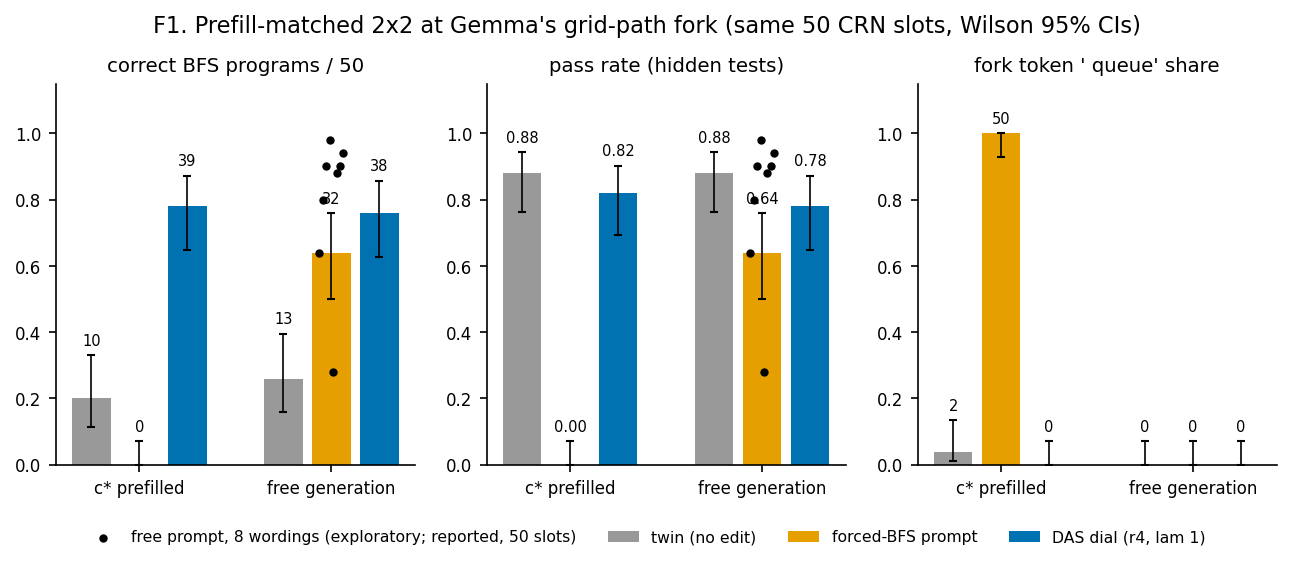

In [31]:
# ---- src/outputs8.py: plot style, palette and figure F1 (adapted for inline display)
def _style() -> None:
    # (outputs8 calls matplotlib.use("Agg") here for file output; dropped so the figures show inline)

    plt.rcParams.update({"font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9, "legend.fontsize": 7.5,
                         "xtick.labelsize": 8, "ytick.labelsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42,
                         "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 150})


PAL = {"prompt": "#E69F00", "dial": "#0072B2", "twin": "#999999", "dim": "#D55E00", "rand": "#CC79A7",
       "dfs": "#009E73", "bfs": "#56B4E9"}


_style()
cells = A["cells"]
A["wording_extension"] = {"by_wording": data["reported"]["wording_extension"]}   # reported: 8 free wordings, full run
# ---------------- F1: the 2x2 (prefilled vs free) x (prompt vs dial), twins beside
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3))
groups = [("c* prefilled", ["P-twin", "G1a", "P-DAS-bfs"]), ("free generation", ["F-twin", "G1c", "F-DAS-r4-bfs-1.0"])]
labels_ = ["twin (no edit)", "forced-BFS prompt", "DAS dial (r4, lam 1)"]
cols = [PAL["twin"], PAL["prompt"], PAL["dial"]]
for ax, (metric, ttl) in zip(axes, (("correct", f"correct BFS programs / {len(S50)}"), ("pass", "pass rate (hidden tests)"),
                                    ("queue", "fork token ' queue' share"))):
    for gi, (gname, cl) in enumerate(groups):
        for j, c in enumerate(cl):
            s = cells.get(c, {})
            if not s.get("n"):
                continue
            n = s["n"]
            if metric == "correct":
                k = s["correct_target"]
            elif metric == "pass":
                k = s["pass"]
            else:
                k = round(s["queue_share"] * n)
            lo, hi = wilson(k, n)                       # outputs8: import analysis8 as A8; A8.wilson
            x = gi * 4 + j
            ax.bar(x, k / n, color=cols[j], width=0.8, label=labels_[j] if gi == 0 else None)
            ax.errorbar(x, k / n, yerr=[[max(k / n - lo, 0.0)], [max(hi - k / n, 0.0)]], color="k", lw=0.8, capsize=2)
            ax.text(x, hi + 0.03, f"{k}" if metric != "pass" else f"{k / n:.2f}", ha="center", fontsize=7)
    we = A.get("wording_extension", {}).get("by_wording", {})
    if we and metric in ("correct", "pass"):
        vals = [(v["correct_bfs"] / 50 if metric == "correct" else v["pass_rate"]) for v in we.values()]
        ax.scatter(np.full(len(vals), 5.0) + np.linspace(-0.25, 0.25, len(vals)), vals, s=9, color="k", zorder=4,
                   label="free prompt, 8 wordings (exploratory; reported, 50 slots)" if metric == "correct" else None)
    ax.set_xticks([1, 5])
    ax.set_xticklabels([g for g, _ in groups])
    ax.set_ylim(0, 1.15)
    ax.set_title(ttl)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"F1. Prefill-matched 2x2 at Gemma's grid-path fork (same {len(S50)} CRN slots, Wilson 95% CIs)", y=1.02)
plt.show()
plt.close(fig)

**Paired outcomes.** Every slot is a row, and every cell in a row shares one random stream. Read across a row to
see what each prompt or edit did to the same sample:
- `G1a` is BFS everywhere but fails everywhere.
- The dial columns turn most DFS slots of the twins into correct BFS.
- The best free wording, `G1e|F3|3`, is correct in 49 of 50 slots.

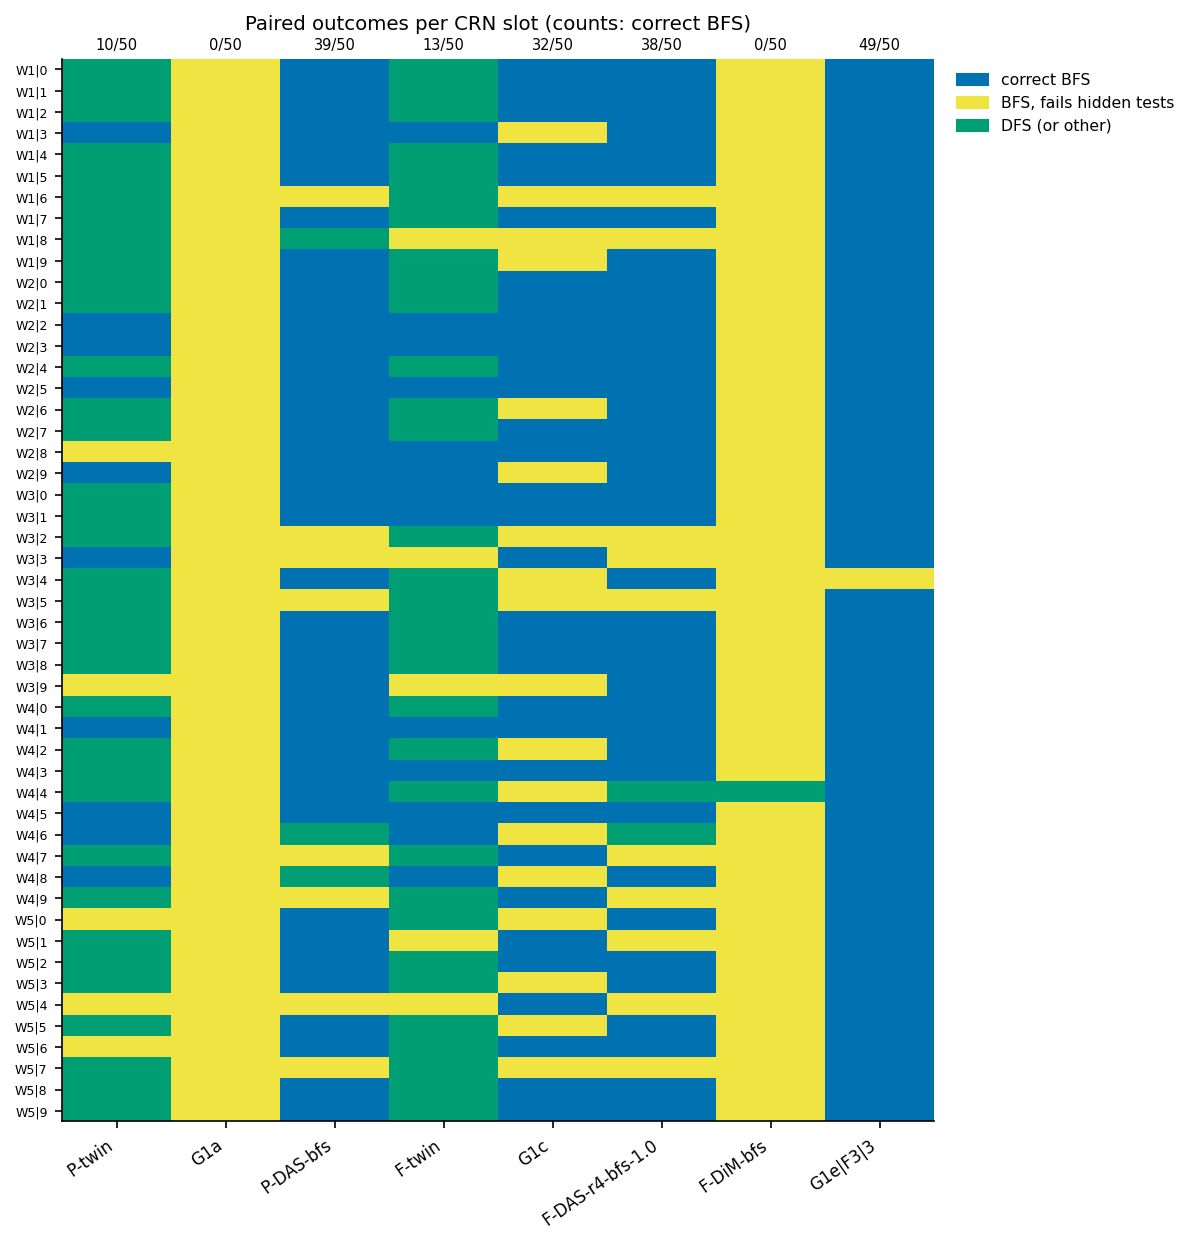

In [32]:
# ---- paired outcomes: one row per CRN slot (same random stream along a row), one column per cell
LAB = {(r["cell"], r["template"], r["slot"]): r for r in labels}
cols_ = [c for c in CELLS_TO_SCORE]
Mx = np.array([[2 if (LAB[(c, w, k)]["label"] == "bfs" and LAB[(c, w, k)]["passed"]) else
                (1 if LAB[(c, w, k)]["label"] == "bfs" else 0) for c in cols_] for (w, k) in S50])
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(7.5, max(2.2, 0.16 * len(S50) + 1.2)))
ax.imshow(Mx, cmap=ListedColormap([PAL["dfs"], "#F0E442", PAL["dial"]]), vmin=0, vmax=2, aspect="auto",
          interpolation="nearest")
ax.set_xticks(range(len(cols_)))
ax.set_xticklabels(cols_, rotation=35, ha="right")
ax.set_yticks(range(len(S50)))
ax.set_yticklabels([f"{w}|{k}" for w, k in S50], fontsize=6)
for j, c in enumerate(cols_):
    ax.text(j, -0.8, f"{int((Mx[:, j] == 2).sum())}/{len(S50)}", ha="center", va="bottom", fontsize=7)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PAL["dial"], label="correct BFS"), Patch(color="#F0E442", label="BFS, fails hidden tests"),
                   Patch(color=PAL["dfs"], label="DFS (or other)")], loc="upper left", bbox_to_anchor=(1.01, 1),
          frameon=False)
ax.set_title("Paired outcomes per CRN slot (counts: correct BFS)", pad=14)
plt.show()

**F3, dormancy by rank k = 1, 2, 4, 8.**
- **(a)** The natural-variance share of R_k on the 120 twins (dots) and on the twins plus the 40 forced sources
  (triangles), against Haar rank-k subspaces (violins) and their 95th percentile. Computed in this notebook.
- **(b)** Retention: the share of the dial's teacher-forced effect that is kept when R_k is projected onto the top
  principal components of the natural states.
- **(c)** Forward and reverse interchange recovery.

Panels (b) and (c) need forward passes of the model, so they are the full run's measurements. The committed
dormancy rule flags DORMANT/OFF-MANIFOLD HANDLE at every k, through retention < 0.5.

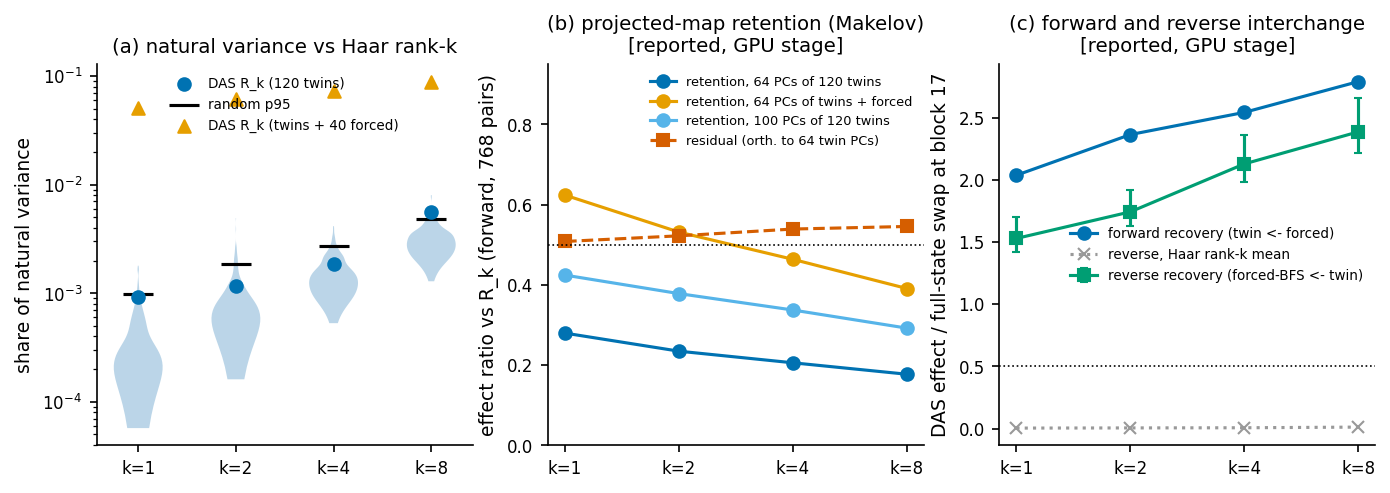

In [33]:
# ---- src/outputs8.py: figure F3, dormancy by rank (panel a computed here; panels b-c: reported GPU measurements)
D = {**G["dormancy_reported"], "natural_variance": {"this_engine_v120": NV120, "this_engine_v160": NV160}}
# ---------------- F3: dormancy by rank
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
ks = ["1", "2", "4", "8"]
# (a) natural variance: Haar distribution (recomputed, generator 9 + k) vs DAS share
# Hv, X: the 120 twin variants decoded above (outputs8: torch.load of cache/states/fork_variants.pt)
Xc = X - X.mean(0, keepdim=True)
Sig = (Xc.T @ Xc) / (X.shape[0] - 1)
trS = float(torch.trace(Sig))
viol = []
for k in ks:
    gq = torch.Generator().manual_seed(9 + int(k))
    rs = []
    for _ in range(N_HAAR_VIOLIN):                                 # outputs8: 300
        Rr = torch.linalg.qr(torch.randn(2560, int(k), generator=gq))[0]
        rs.append(float(torch.trace(Rr.T @ Sig @ Rr)) / trS)
    viol.append(rs)
nv = D["natural_variance"]["this_engine_v120"]
nv160 = D["natural_variance"]["this_engine_v160"]
axes[0].violinplot(viol, positions=range(4), showextrema=False)
axes[0].scatter(range(4), [nv[k]["share"] for k in ks], color=PAL["dial"], zorder=3, label="DAS R_k (120 twins)")
axes[0].scatter(range(4), [nv[k]["random_p95"] for k in ks], marker="_", s=200, color="k", label="random p95")
axes[0].scatter(range(4), [nv160[k]["share"] for k in ks], color=PAL["prompt"], marker="^", zorder=3,
                label="DAS R_k (twins + 40 forced)")
axes[0].set_yscale("log")
axes[0].set_xticks(range(4))
axes[0].set_xticklabels([f"k={k}" for k in ks])
axes[0].set_ylabel("share of natural variance")
axes[0].set_title("(a) natural variance vs Haar rank-k")
axes[0].legend(frameon=False, fontsize=6.5)
pr = D["projection"]
for nm, col, lab in (("pc64_v120", PAL["dial"], "retention, 64 PCs of 120 twins"),
                     ("pc64_v160", PAL["prompt"], "retention, 64 PCs of twins + forced"),
                     ("pc100_v120", PAL["bfs"], "retention, 100 PCs of 120 twins")):
    axes[1].plot(range(4), [pr[k][nm]["retention_interchange"]["estimate"] for k in ks], "o-", color=col, label=lab)
axes[1].plot(range(4), [pr[k]["pc64_v120"]["residual_interchange"]["estimate"] for k in ks], "s--", color=PAL["dim"],
             label="residual (orth. to 64 twin PCs)")
axes[1].axhline(0.5, ls=":", color="k", lw=0.8)
axes[1].set_xticks(range(4))
axes[1].set_xticklabels([f"k={k}" for k in ks])
axes[1].set_ylabel("effect ratio vs R_k (forward, 768 pairs)")
axes[1].set_title("(b) projected-map retention (Makelov)\n[reported, GPU stage]")
axes[1].set_ylim(0, 0.95)
axes[1].legend(frameon=False, fontsize=6.2, loc="upper right", ncol=1)
fw = [D["forward"]["by"][f"seed0_k{k}"]["median_recovery"] for k in ks]
rv = [D["reverse"]["by_k"][k]["held"]["reverse_recovery"] for k in ks]
rci = [D["reverse"]["by_k"][k]["held"]["reverse_recovery_ci95"] for k in ks]
axes[2].plot(range(4), fw, "o-", color=PAL["dial"], label="forward recovery (twin <- forced)")
axes[2].errorbar(range(4), rv, yerr=[[max(r - c[0], 0) for r, c in zip(rv, rci)], [max(c[1] - r, 0) for r, c in zip(rv, rci)]],
                 fmt="s-", color=PAL["dfs"], capsize=2, label="reverse recovery (forced-BFS <- twin)")
hn = [D["reverse"]["by_k"][k]["held"]["haar_null_mean"] / D["reverse"]["by_k"][k]["held"]["dm_full_mean"] for k in ks]
axes[2].plot(range(4), hn, "x:", color=PAL["twin"], label="reverse, Haar rank-k mean")
axes[2].axhline(0.5, ls=":", color="k", lw=0.8)
axes[2].set_xticks(range(4))
axes[2].set_xticklabels([f"k={k}" for k in ks])
axes[2].set_ylabel("DAS effect / full-state swap at block 17")
axes[2].set_title("(c) forward and reverse interchange\n[reported, GPU stage]")
axes[2].legend(frameon=False, fontsize=6.5)
plt.show()
plt.close(fig)

**F4** projects each group of states onto two planes: the first two DAS directions (R_1, R_2) and the first two
principal components of the 120 twin variants. The groups are:
- the 120 twin variants, coloured by fork margin;
- the forced-BFS and forced-DFS sources;
- the free twin at its decision position;
- the same states after the dial toward BFS, after the dial toward DFS, and after DiM.

- **DAS plane (left).** The forced-BFS and forced-DFS sources form two separate clusters, and the twins sit
  nearer the DFS cluster. The dial moves each twin state exactly onto the BFS class mean, among the forced-BFS
  sources, or onto the DFS class mean. DiM at matched strength overshoots far from both clusters, and its
  programs break (0/50 correct).
- **PC plane (right).** In the plane of the twins' own top-2 principal components the dial-edited states hardly
  move. The dial acts along directions that the twins' natural, noun-driven variation hardly uses, which is the
  natural-variance result above.

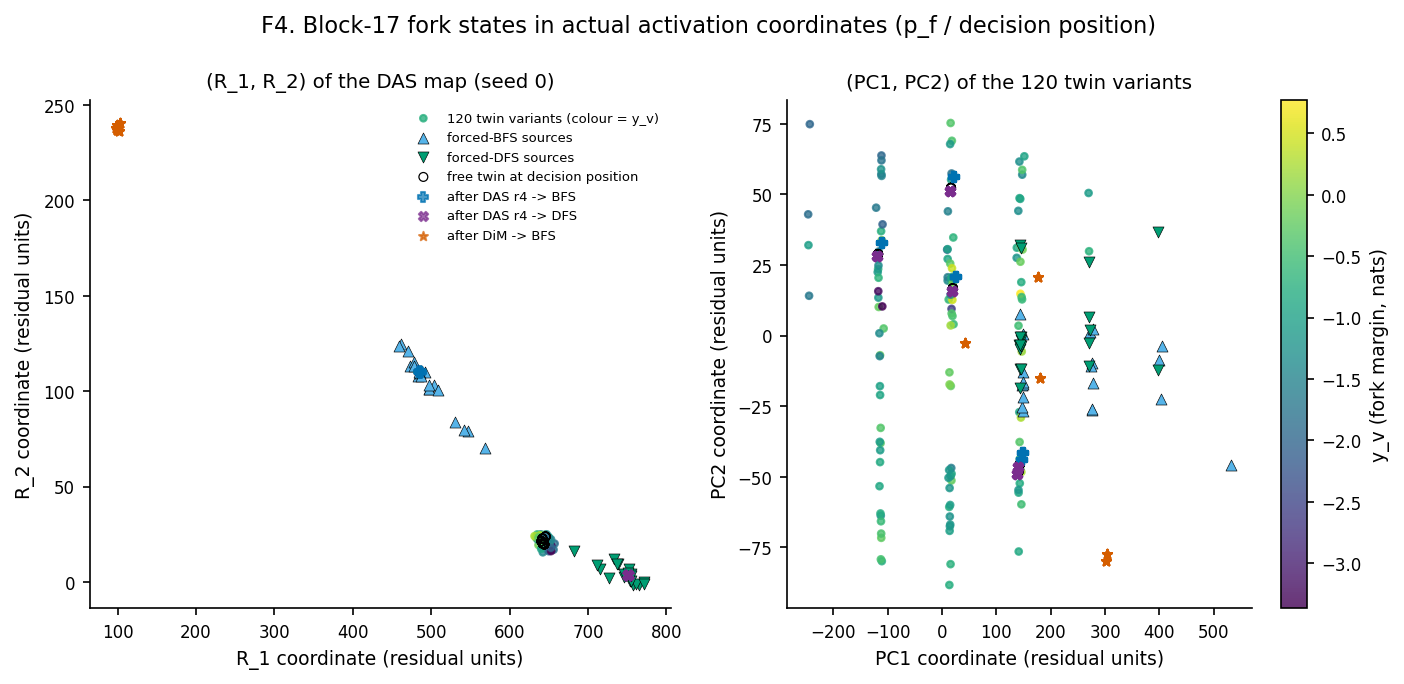

In [34]:
# ---- src/outputs8.py: figure F4, block-17 fork states in actual activation coordinates (adapted for inline display)
# ---------------- F4: geometry in block-17 activation coordinates
# maps, u, X, Hs, S7, c3: decoded above (outputs8: torch.load / read_json of the cached files)
R = maps[0][:, :2]
yv = np.array([v["y"] for v in Hv])
_tw = G["decision_states_by_template"]["templates"]     # outputs8: cache/decision_states.pt, one state per R1 slot
geo = {e["slot_id"]: {"h": Hd5[_tw.index(e["template"])]} for e in data["examples"] if e["decision"]["reach_type"] == "R1"}
Hd = torch.stack([g["h"] for g in geo.values()]).float()
R4 = maps[0][:, :4]
edited = {}
for Y in ("bfs", "dfs"):
    cY = torch.tensor(c3[Y])
    edited[Y] = Hd + ((cY[None] - Hd @ R4) @ R4.T)
tfs = {"dim_betas": {Y: {"beta": b} for Y, b in G["dim_beta"].items()}}   # outputs8: results/tf_stage.json
edited["dim_bfs"] = Hd + tfs["dim_betas"]["bfs"]["beta"] * u[None]
mu = X.mean(0)
U, Sv, Vt = torch.linalg.svd(X - mu, full_matrices=False)
P2 = Vt[:2].T
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, B, nm in ((axes[0], R, "(R_1, R_2) of the DAS map (seed 0)"), (axes[1], P2, "(PC1, PC2) of the 120 twin variants")):
    off = mu @ B if B is P2 else torch.zeros(2)
    pv = (X @ B - off).numpy()
    ps = (Hs @ B - off).numpy()
    pdd = (Hd @ B - off).numpy()
    sc = ax.scatter(pv[:, 0], pv[:, 1], c=yv, cmap="viridis", s=10, alpha=0.8, label="120 twin variants (colour = y_v)")
    mb = np.array([s["mode"] == "bfs" for s in S7])
    ax.scatter(ps[mb, 0], ps[mb, 1], marker="^", color=PAL["bfs"], edgecolor="k", lw=0.3, s=28, label="forced-BFS sources")
    ax.scatter(ps[~mb, 0], ps[~mb, 1], marker="v", color=PAL["dfs"], edgecolor="k", lw=0.3, s=28, label="forced-DFS sources")
    ax.scatter(pdd[:, 0], pdd[:, 1], marker="o", facecolor="none", edgecolor="k", s=18, lw=0.6,
               label="free twin at decision position")
    for Y, col, mk in (("bfs", PAL["dial"], "P"), ("dfs", "#7B2D8E", "X"), ("dim_bfs", PAL["dim"], "*")):
        pe = (edited[Y] @ B - off).numpy()
        ax.scatter(pe[:, 0], pe[:, 1], marker=mk, color=col, s=20, alpha=0.7,
                   label={"bfs": "after DAS r4 -> BFS", "dfs": "after DAS r4 -> DFS", "dim_bfs": "after DiM -> BFS"}[Y])
    ax.set_xlabel(("R_1" if B is R else "PC1") + " coordinate (residual units)")
    ax.set_ylabel(("R_2" if B is R else "PC2") + " coordinate (residual units)")
    ax.set_title(nm)
axes[0].legend(frameon=False, fontsize=6.3, loc="best")
fig.colorbar(sc, ax=axes[1], label="y_v (fork margin, nats)")
fig.suptitle("F4. Block-17 fork states in actual activation coordinates (p_f / decision position)", y=1.01)
plt.show()
plt.close(fig)

## Summary: this notebook vs the full run

At `N_SLOTS_PER_TEMPLATE = 10`, with the full-run resampling sizes, every number below equals the artifact's
published value. The cell asserts this. At smaller settings the same quantities are computed on fewer slots.

In [35]:
rep = data["reported"]
full = len(S50) == 50 and N_BOOT_SLOTS == 10000 and N_HAAR_VAR == 1000
rows = [(f"correct BFS, {c}", A["cells"][c]["correct_target"], len(S50), rep["cells"][c]["correct_target"], 50) for c in CELLS_TO_SCORE]
for key, name in (("dial_vs_prompt_prefilled_P1b", "P1b dial vs prompt, prefilled"), ("dial_vs_prompt_free", "dial vs prompt, free"),
                  ("prefilled_vs_free_dial", "dial: prefilled vs free")):
    rows.append((f"{name}: discordant", f"{T[key]['a_only']}/{T[key]['b_only']}", None,
                 f"{rep['tests'][key]['a_only']}/{rep['tests'][key]['b_only']}", None))
    rows.append((f"{name}: p (two-sided)", f"{T[key]['p_two_sided']:.3g}", None, f"{rep['tests'][key]['p_two_sided']:.3g}", None))
rows.append(("interaction (slot bootstrap)", f"{ia['interaction']:.2f} [{ia['ci95'][0]:.2f}, {ia['ci95'][1]:.2f}]", None,
             f"{rep['interaction_slot_bootstrap']['interaction']:.2f} [{rep['interaction_slot_bootstrap']['ci95'][0]:.2f}, "
             f"{rep['interaction_slot_bootstrap']['ci95'][1]:.2f}]", None))
for kk in ("1", "4"):
    rows.append((f"natural-variance share k={kk} (p95)", f"{NV120[kk]['share']:.5f} ({NV120[kk]['random_p95']:.5f})", None,
                 f"{G['reported_natural_variance']['iter7_cached_v120'][kk]['share']:.5f} "
                 f"({G['reported_natural_variance']['iter7_cached_v120'][kk]['random_p95']:.5f})", None))
print(f"{'quantity':42s} {'this notebook':>24s} {'full run (reported)':>24s}")
for name, a, na, b, nb in rows:
    sa = f"{a}/{na}" if na else str(a)
    sb = f"{b}/{nb}" if nb else str(b)
    print(f"{name:42s} {sa:>24s} {sb:>24s}")
if full:
    assert all(A["cells"][c]["correct_target"] == rep["cells"][c]["correct_target"] for c in CELLS_TO_SCORE)
    assert all(T[k]["a_only"] == rep["tests"][k]["a_only"] and T[k]["b_only"] == rep["tests"][k]["b_only"]
               for k in ("dial_vs_prompt_prefilled_P1b", "dial_vs_prompt_free", "prefilled_vs_free_dial"))
    assert abs(ia["interaction"] - rep["interaction_slot_bootstrap"]["interaction"]) < 1e-12
    assert all(abs(x - y) < 1e-9 for x, y in zip(ia["ci95"], rep["interaction_slot_bootstrap"]["ci95"]))
    assert all(abs(NV120[kk]["share"] - G["reported_natural_variance"]["iter7_cached_v120"][kk]["share"]) < 1e-6 for kk in NV120 if kk in "1248")
    print("\nfull-scale run: every recomputed number above equals the artifact's published value")
else:
    print(f"\ndemo scale ({len(S50)} slots, {N_BOOT_SLOTS} bootstrap resamples, {N_HAAR_VAR} Haar draws): "
          "set N_SLOTS_PER_TEMPLATE = 10 and the full-run sizes to reproduce the published numbers exactly")

quantity                                              this notebook      full run (reported)
correct BFS, P-twin                                           10/50                    10/50
correct BFS, G1a                                               0/50                     0/50
correct BFS, P-DAS-bfs                                        39/50                    39/50
correct BFS, F-twin                                           13/50                    13/50
correct BFS, G1c                                              32/50                    32/50
correct BFS, F-DAS-r4-bfs-1.0                                 38/50                    38/50
correct BFS, F-DiM-bfs                                         0/50                     0/50
correct BFS, G1e|F3|3                                         49/50                    49/50
P1b dial vs prompt, prefilled: discordant                      39/0                     39/0
P1b dial vs prompt, prefilled: p (two-sided)                 3.64e-12 

## Notes

**Adaptations made for the notebook** (all marked in the code comments):
1. **Inputs.** They come from `mini_demo_data.json` (GitHub URL with a local fallback), not from the artifact
   folders. `ROOT` is the working directory, and `cfg.py`'s folder creation is skipped.
2. **Configuration.** `cfg8.S50`, `N_BOOT_SLOTS` and `N_HAAR_VAR` come from the configuration cell, as do the
   placebo count, the test workers and the F3 violin draws.
3. **Modules.** `cfg` and `cfg8` are registered as modules, so the original `from cfg8 import ...` lines run
   unchanged.
4. **Labelling.** Programs are labelled by the artifact's independent standard-library re-scorer,
   `audit/rederive_raw.py`. It agrees with the frozen exp8 labeller on all 400 shipped programs. `run_tests` is a
   thin wrapper around that runner.
5. **CPU.** `tf8.natural_variance` runs on CPU (`.cuda()` dropped).
6. **Figures.** In the `outputs8` figures, inline display replaces `Agg` and file saving, and the decoded arrays
   replace `torch.load`. Numbers that only the GPU stages produce are labelled "reported".
7. **GPU stages.** They are defined verbatim but not called.

**The full pipeline.** In a checkout of the artifact folder, with a CUDA GPU, `HF_TOKEN` for the gated
`google/gemma-3-4b-it` and the inputs restored (`bash restore.sh`), run
`python method.py --stage <s0|label|gpu1|commit2|fcells|gpu_extra|tf_extra|novelty|positioning|analysis|figures|outputs>`
in the order given in the artifact's `reproducibility.md`. It takes about 13 GPU-minutes and 45 minutes of wall
time.